# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [26]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [2]:
#!rm SUSY.csv

In [9]:
!gunzip SUSY.csv.gz

gzip: SUSY.csv.gz: No such file or directory


In [10]:
!ls -lh

total 2.3G
-rw-r--r-- 1 ecook ecook 358K Oct 19 13:24 Lab.7.Solutions.ipynb
-rw-r--r-- 1 ecook ecook 357K Oct  9 13:02 Lab.7.ipynb
-rw-r--r-- 1 ecook ecook 150K Oct  9 13:02 Lab.7.pdf
-rw-r--r-- 1 ecook ecook 2.3G Oct 19 13:22 SUSY.csv


The data is provided as a comma separated file.

In [1]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [12]:
!ls -lh

total 2.3G
-rw-r--r-- 1 ecook ecook 358K Oct 19 13:30 Lab.7.Solutions.ipynb
-rw-r--r-- 1 ecook ecook 357K Oct  9 13:02 Lab.7.ipynb
-rw-r--r-- 1 ecook ecook 150K Oct  9 13:02 Lab.7.pdf
-rw-r--r-- 1 ecook ecook 2.3G Oct 19 13:22 SUSY.csv


We see that we have 5 million datapoints.

In [13]:
!wc -l SUSY.csv

5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [14]:
!head -500000 SUSY.csv > SUSY-small.csv

In [15]:
ls -lh

total 2.5G
-rw-r--r-- 1 ecook ecook 358K Oct 19 13:30 Lab.7.Solutions.ipynb
-rw-r--r-- 1 ecook ecook 357K Oct  9 13:02 Lab.7.ipynb
-rw-r--r-- 1 ecook ecook 150K Oct  9 13:02 Lab.7.pdf
-rw-r--r-- 1 ecook ecook 228M Oct 19 13:30 SUSY-small.csv
-rw-r--r-- 1 ecook ecook 2.3G Oct 19 13:22 SUSY.csv


In [16]:
! wc -l SUSY-small.csv

500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [3]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [4]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [19]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [5]:
FeatureNames

['MT2',
 'cos_theta_r1',
 'S_R',
 'axial_MET',
 'M_R',
 'R',
 'M_TR_2',
 'dPhi_r_b',
 'M_Delta_R',
 'MET_rel']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [10]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [9]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [11]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


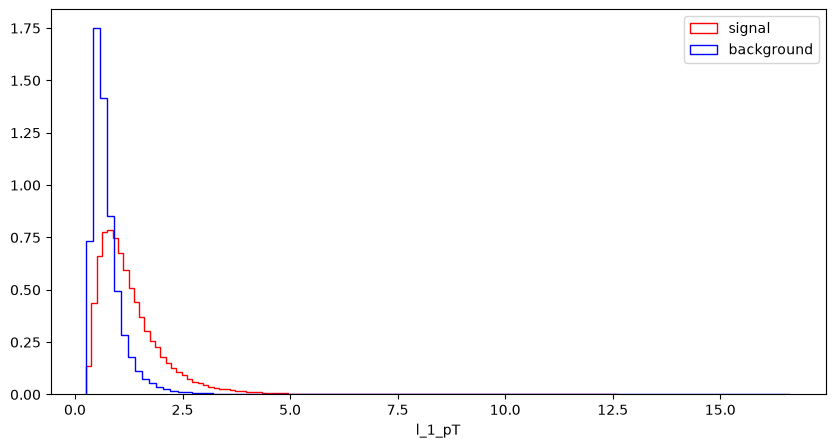

l_1_eta


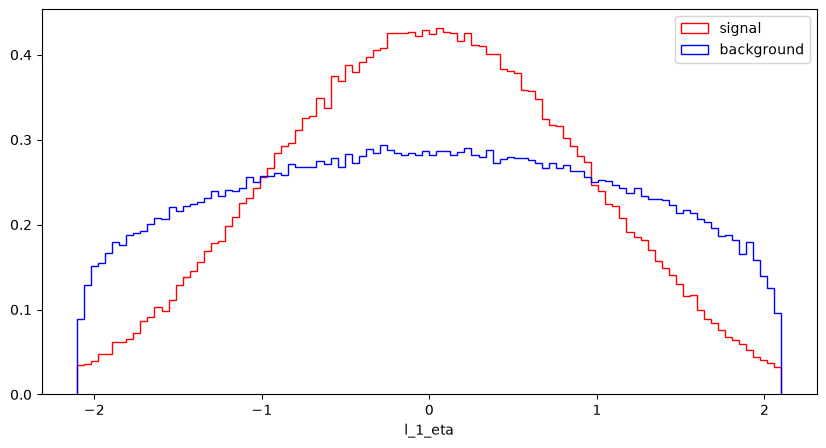

l_1_phi


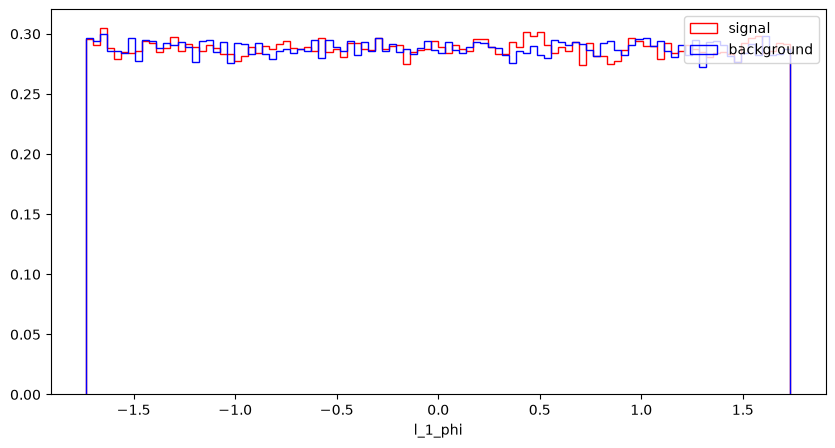

l_2_pT


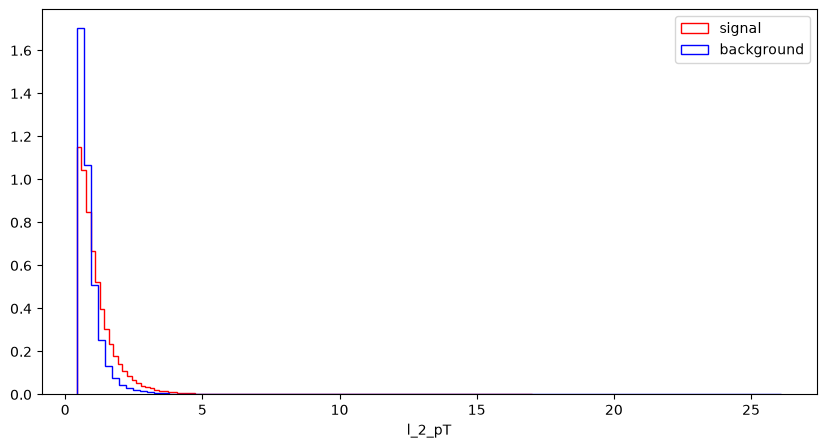

l_2_eta


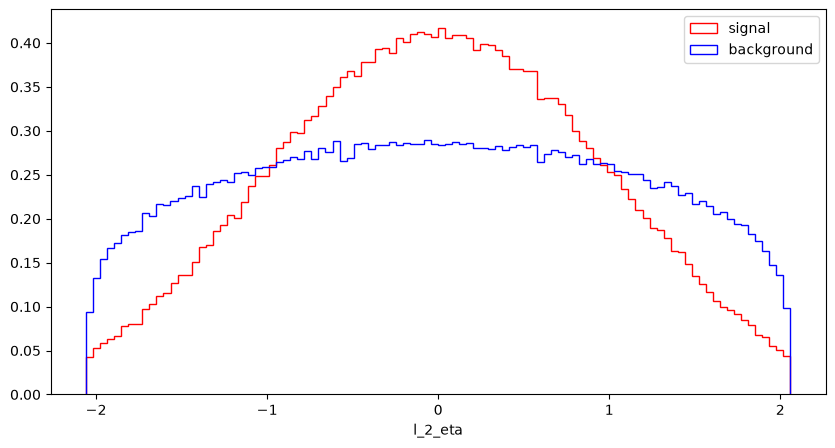

l_2_phi


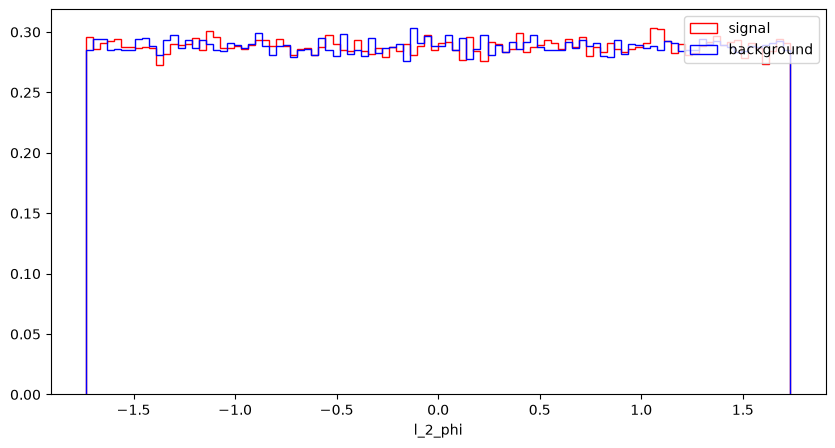

MET


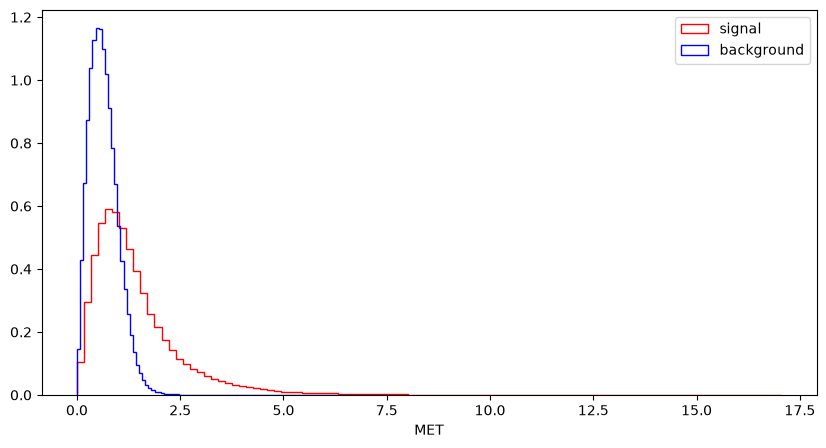

MET_phi


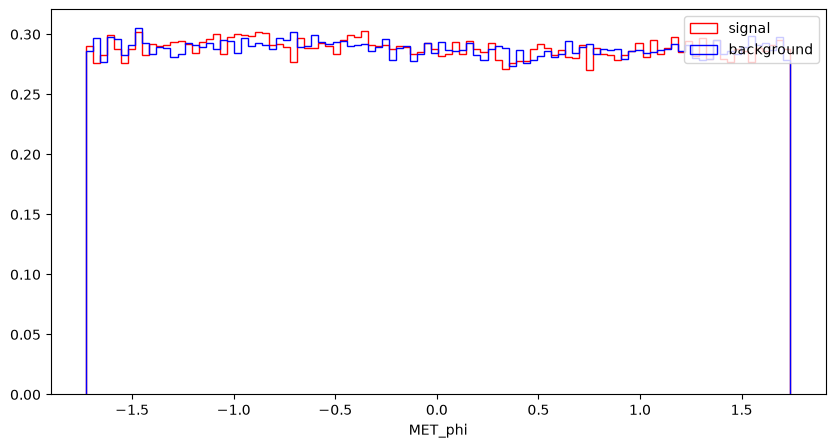

MET_rel


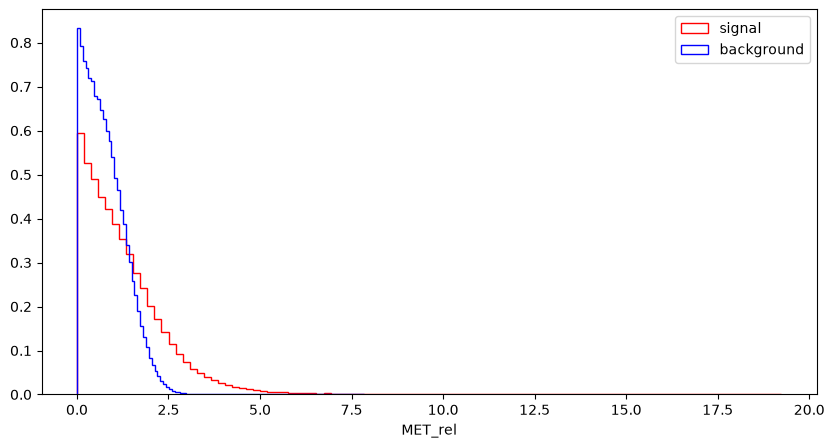

axial_MET


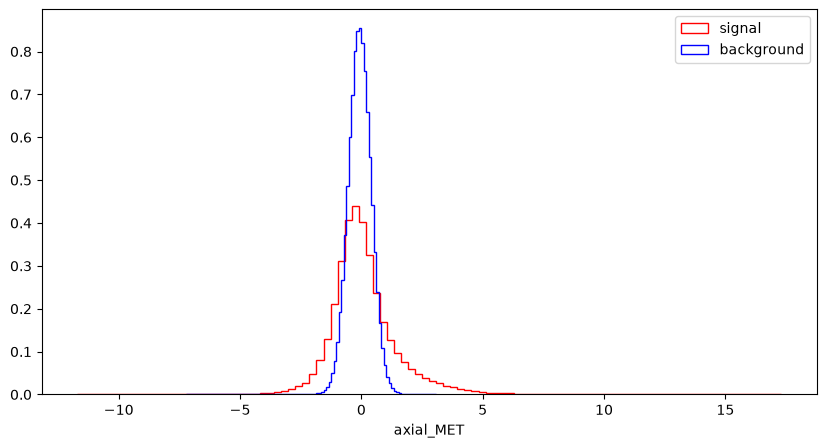

M_R


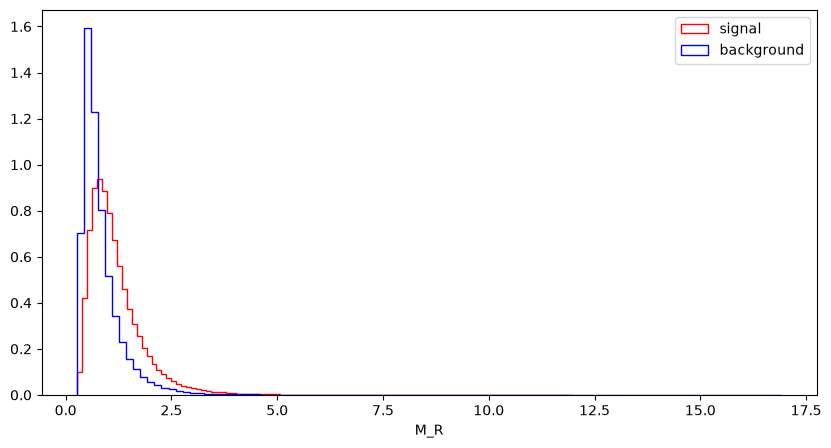

M_TR_2


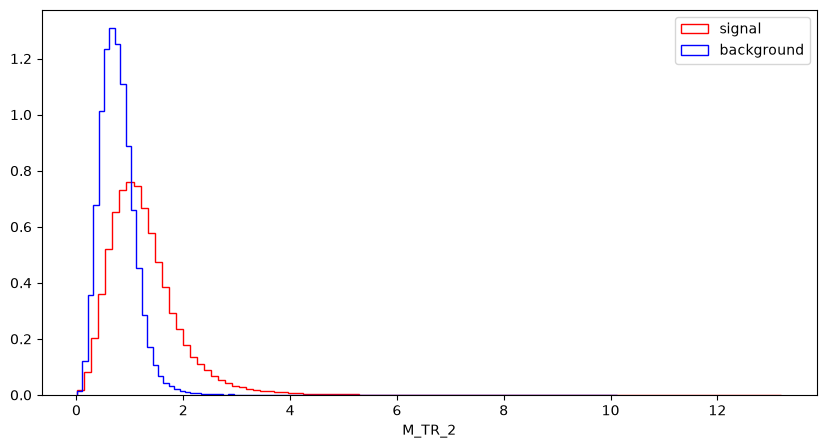

R


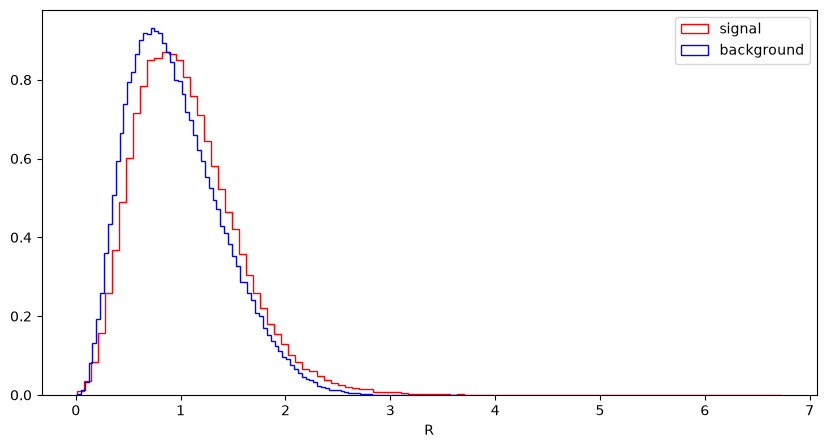

MT2


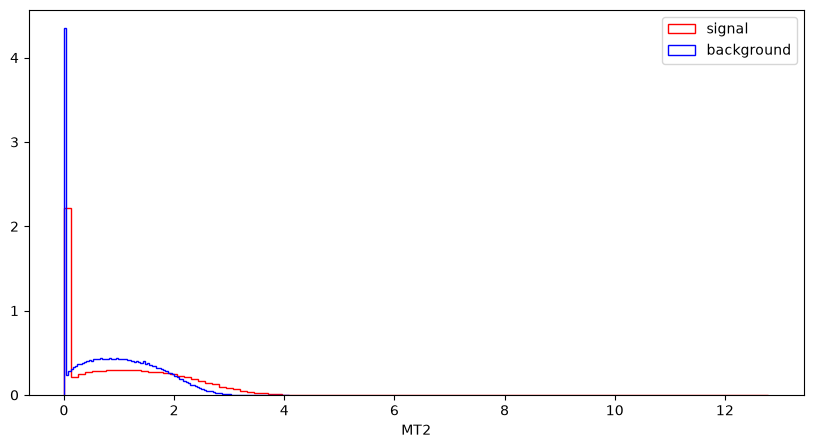

S_R


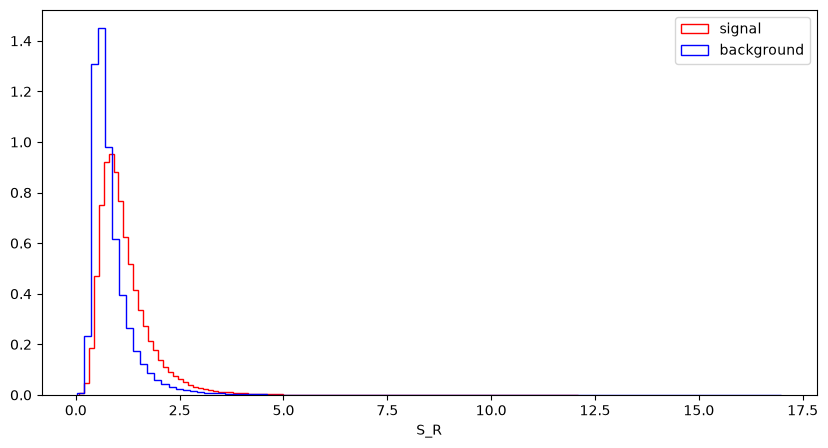

M_Delta_R


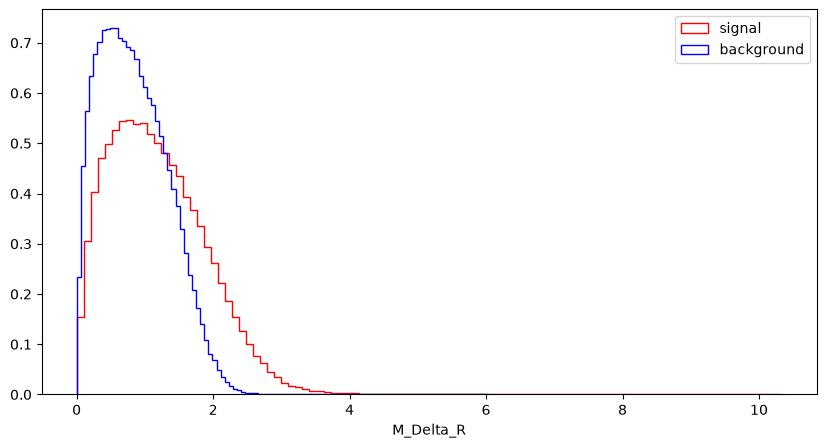

dPhi_r_b


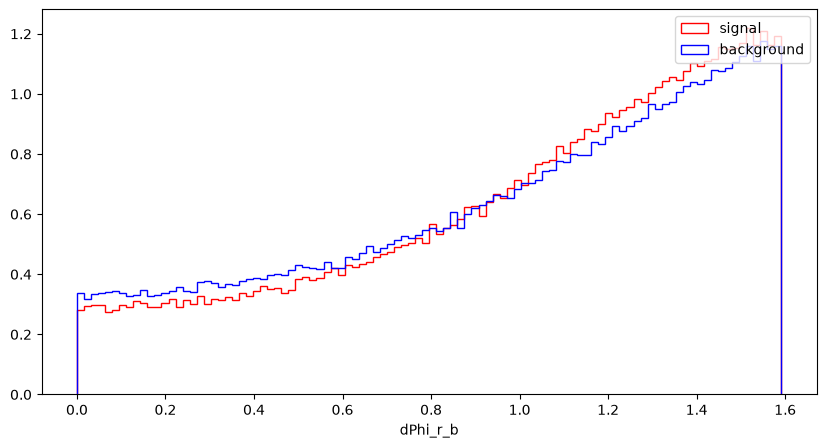

cos_theta_r1


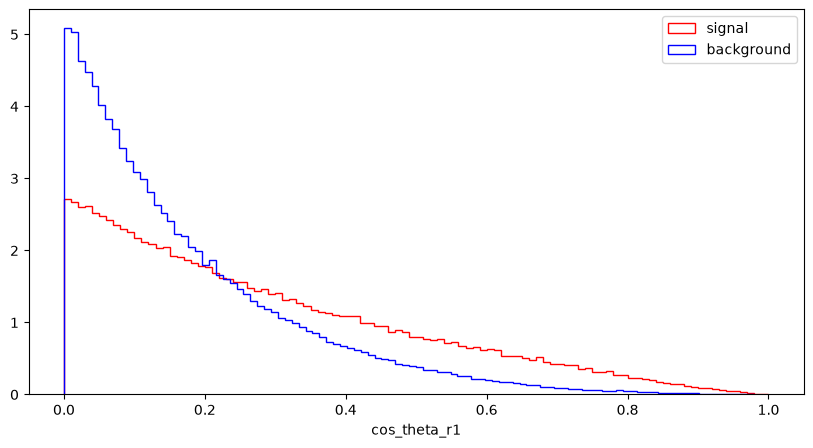

In [24]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.xlabel(var)
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

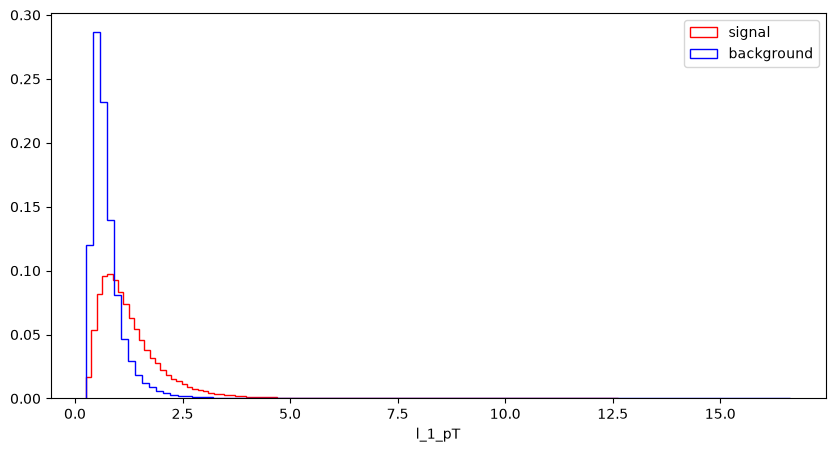

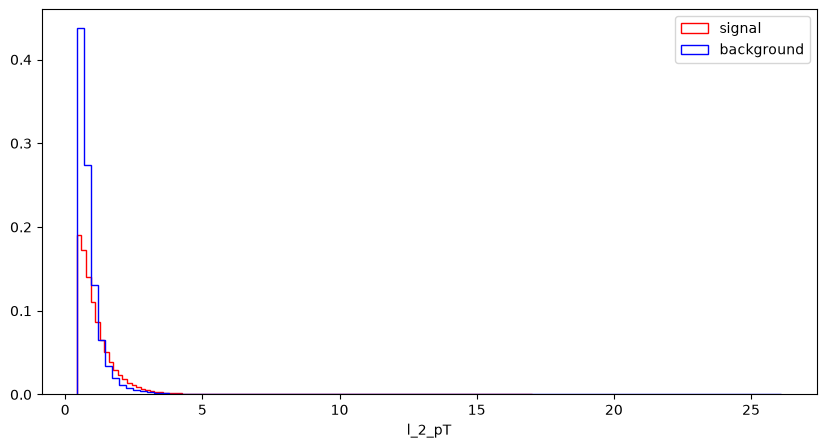

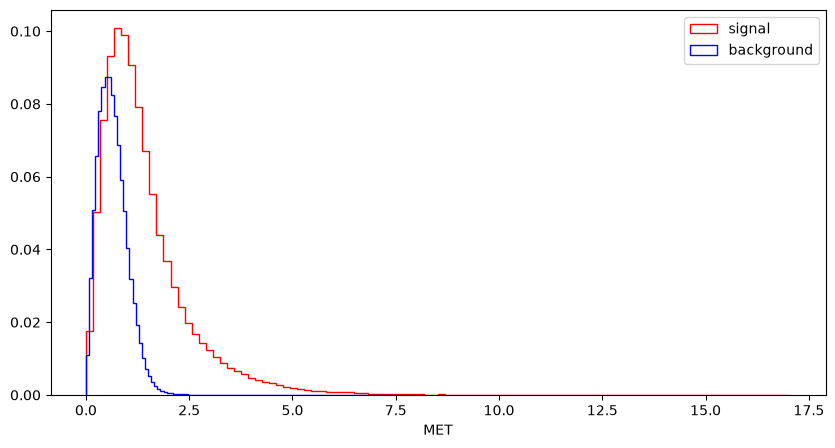

In [18]:
# Figure 5, low-level input features
# l_1_pT - lepton 1 pT
# l_2_pt - lepton 2 pT
# MET - Missing Transverse Momentum
# sum jet pT and N jets variables missing
for var in VarNames[1:]:
    if var in ('l_1_pT', 'l_2_pT', 'MET'):
        plt.figure(figsize=(10,5))
        plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",weights=np.ones(len(df_sig[var])) / len(df_sig[var]), stacked=True)
        plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",weights=np.ones(len(df_bkg[var])) / len(df_bkg[var]), stacked=True)
        plt.legend(loc='upper right')
        plt.xlabel(var)
        plt.show()

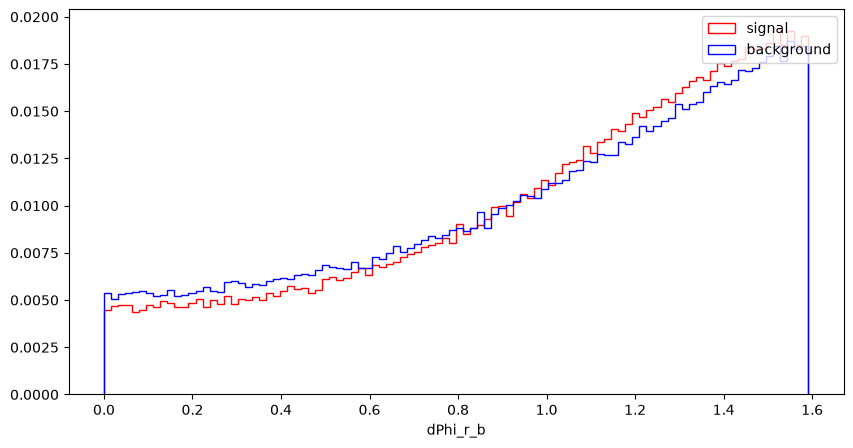

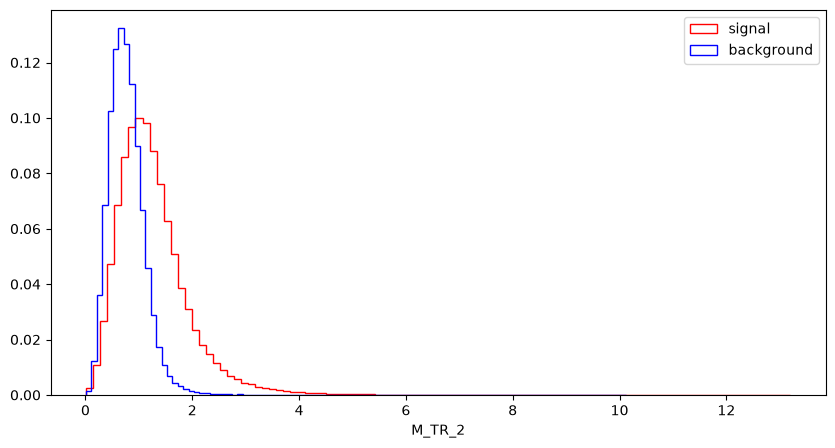

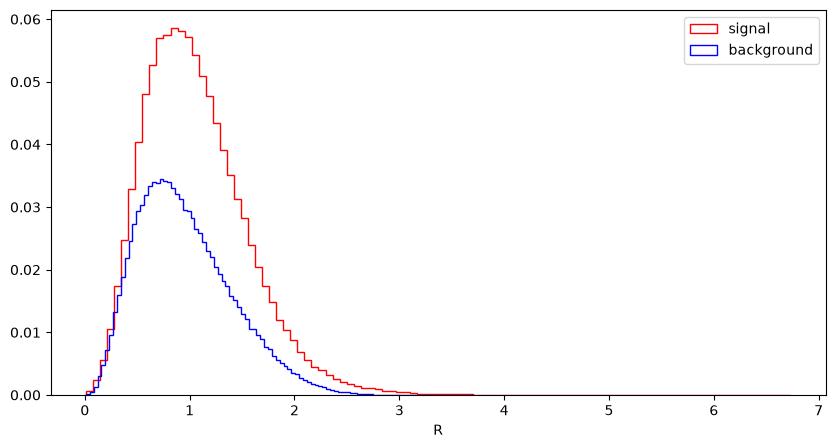

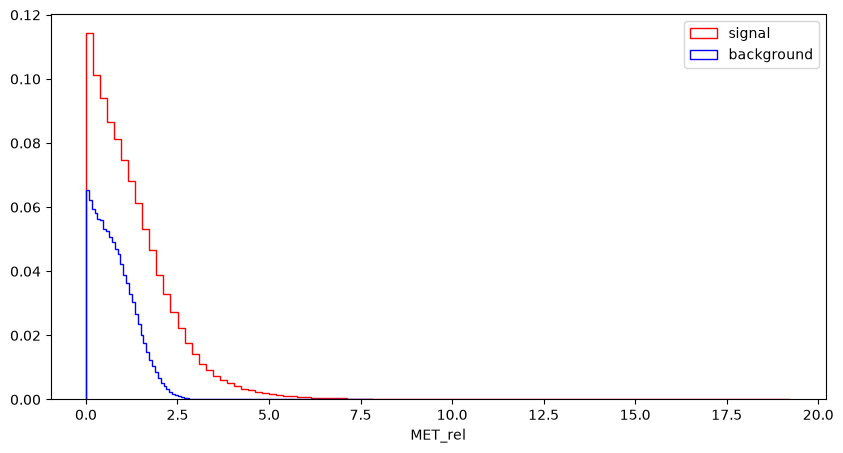

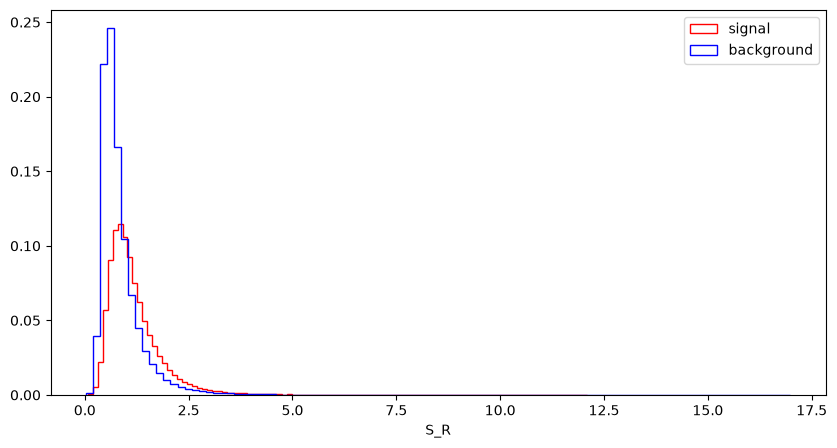

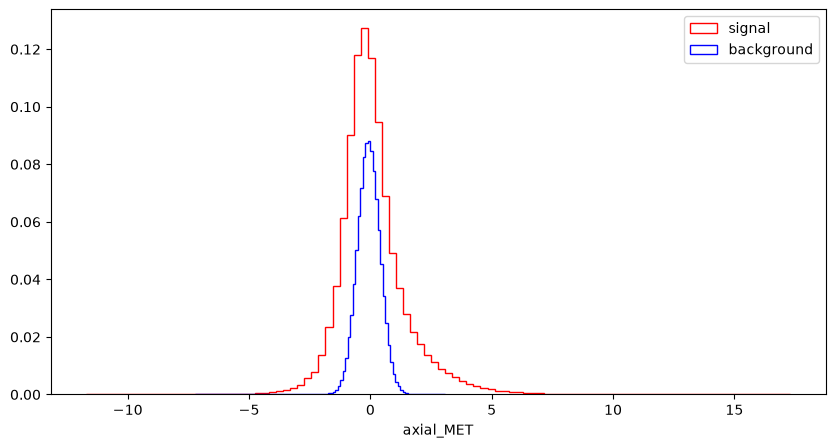

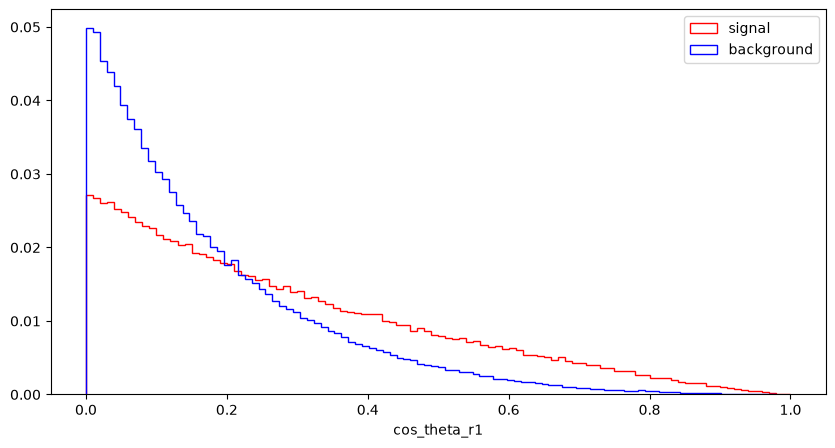

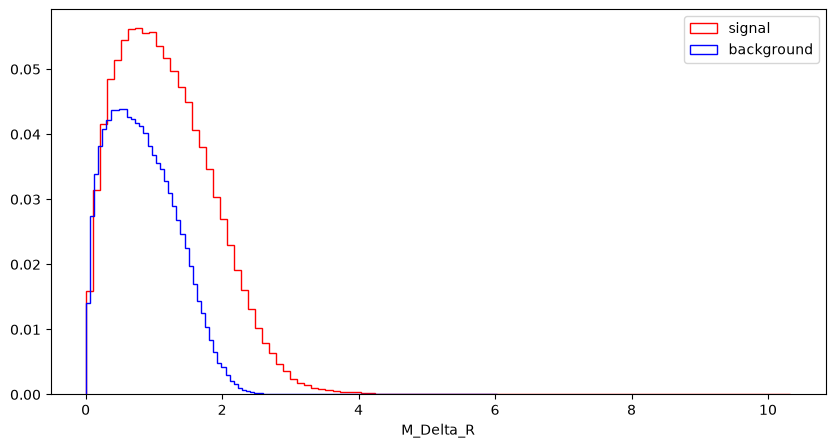

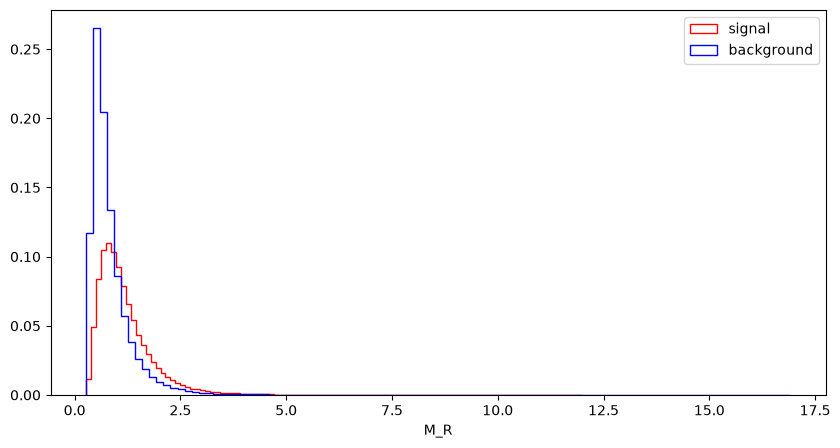

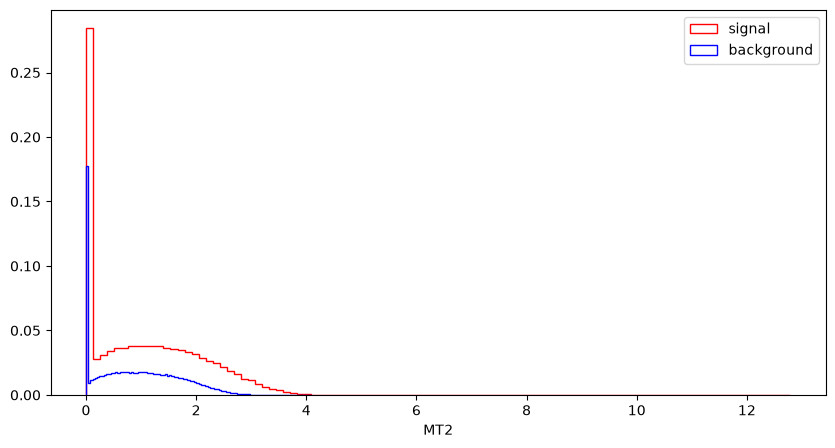

In [20]:
# Figure 6, high-level input features
for feat in FeatureNames:
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[feat]),bins=100,histtype="step", color="red",label="signal",weights=np.ones(len(df_sig[feat])) / len(df_sig[feat]), stacked=True)
    plt.hist(np.array(df_bkg[feat]),bins=100,histtype="step", color="blue", label="background",weights=np.ones(len(df_bkg[feat])) / len(df_bkg[feat]), stacked=True)
    plt.legend(loc='upper right')
    plt.xlabel(feat)
    plt.show()

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

In [20]:
# Part a
def compare_distributions(df,column_name,selections,bins=10,**kwargs):
    for label,selection in selections.items():
        _,bins,_=plt.hist(selection[column_name],bins=bins,label=label,**kwargs)

    _=plt.legend()

In [21]:
# part a
selection_dict={"Signal":df_sig,"Background":df_bkg}

def compare_scatter(df,x_var_name,y_var_name,selections,make_legend=True) :
    for label,selection in selections.items():   
        _=plt.scatter(selection[x_var_name],selection[y_var_name],label=label, s=0.5)

    _=plt.xlabel(x_var_name)
    _=plt.ylabel(y_var_name)

    if make_legend:
        _=plt.legend()

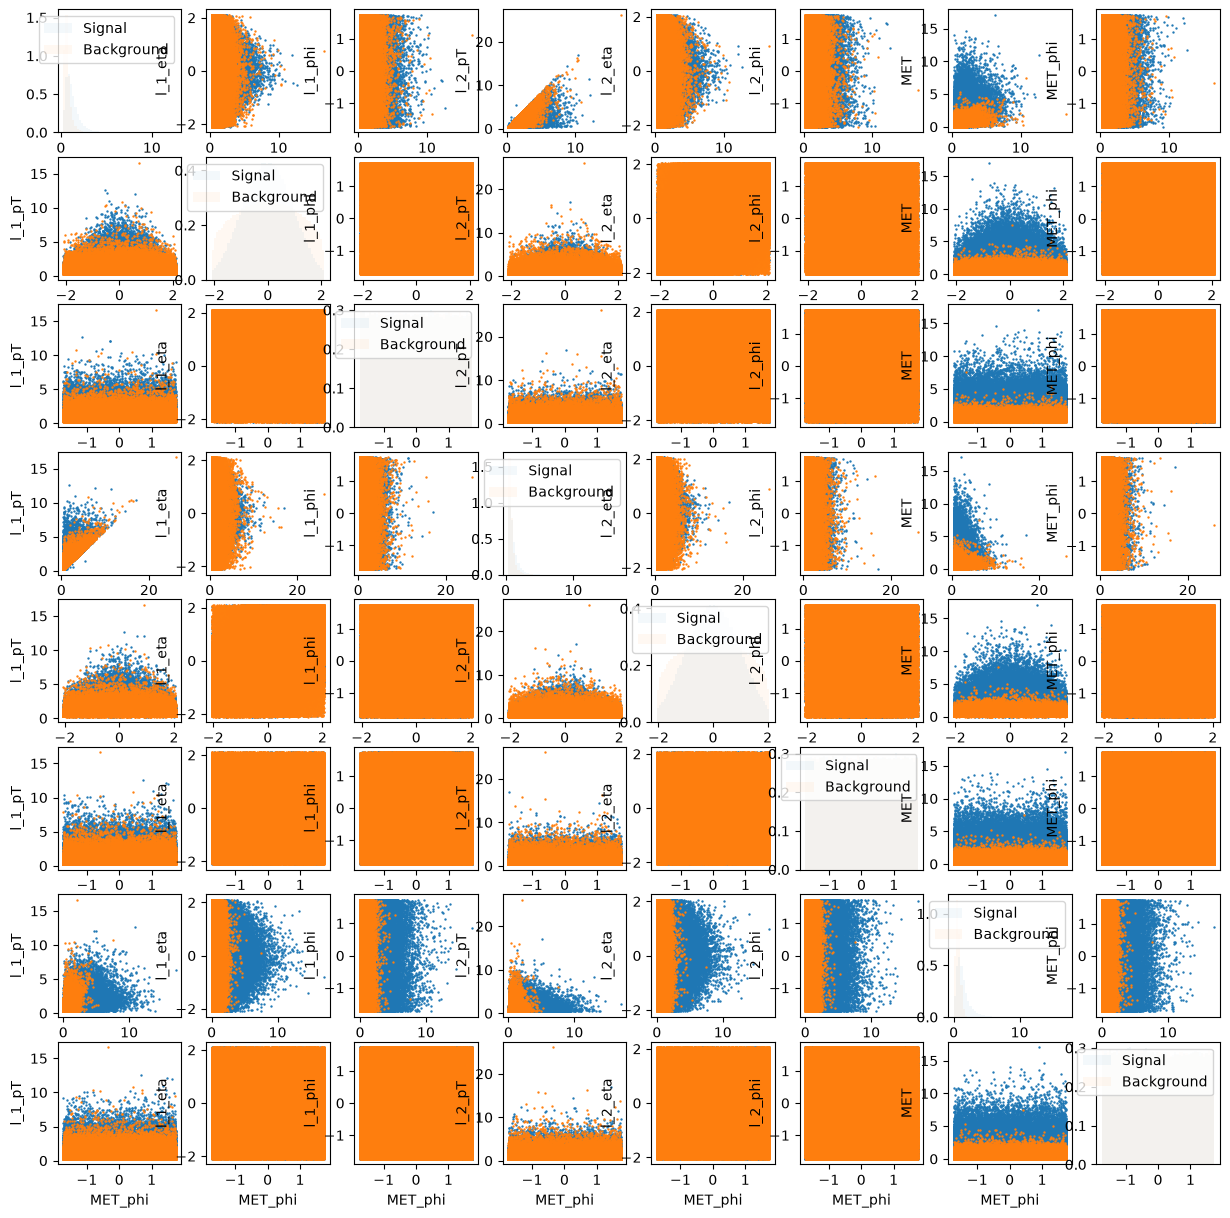

In [23]:
# part a
columns = df.columns[1:9]
n_columns=len(columns)
plt.figure(figsize=(15,15))

plot_i=0
for i,x_var_name in enumerate(columns):
    for j,y_var_name in enumerate(columns):
        plot_i+=1
        plt.subplot(n_columns,n_columns,plot_i)
        make_legend = plot_i==1
        if i==j:
            compare_distributions(df,x_var_name,
                     selection_dict,
                     alpha=0.05,
                     density=1,
                     bins=50,
                     )
        else:
            compare_scatter(df,x_var_name,y_var_name,selection_dict,make_legend=make_legend)

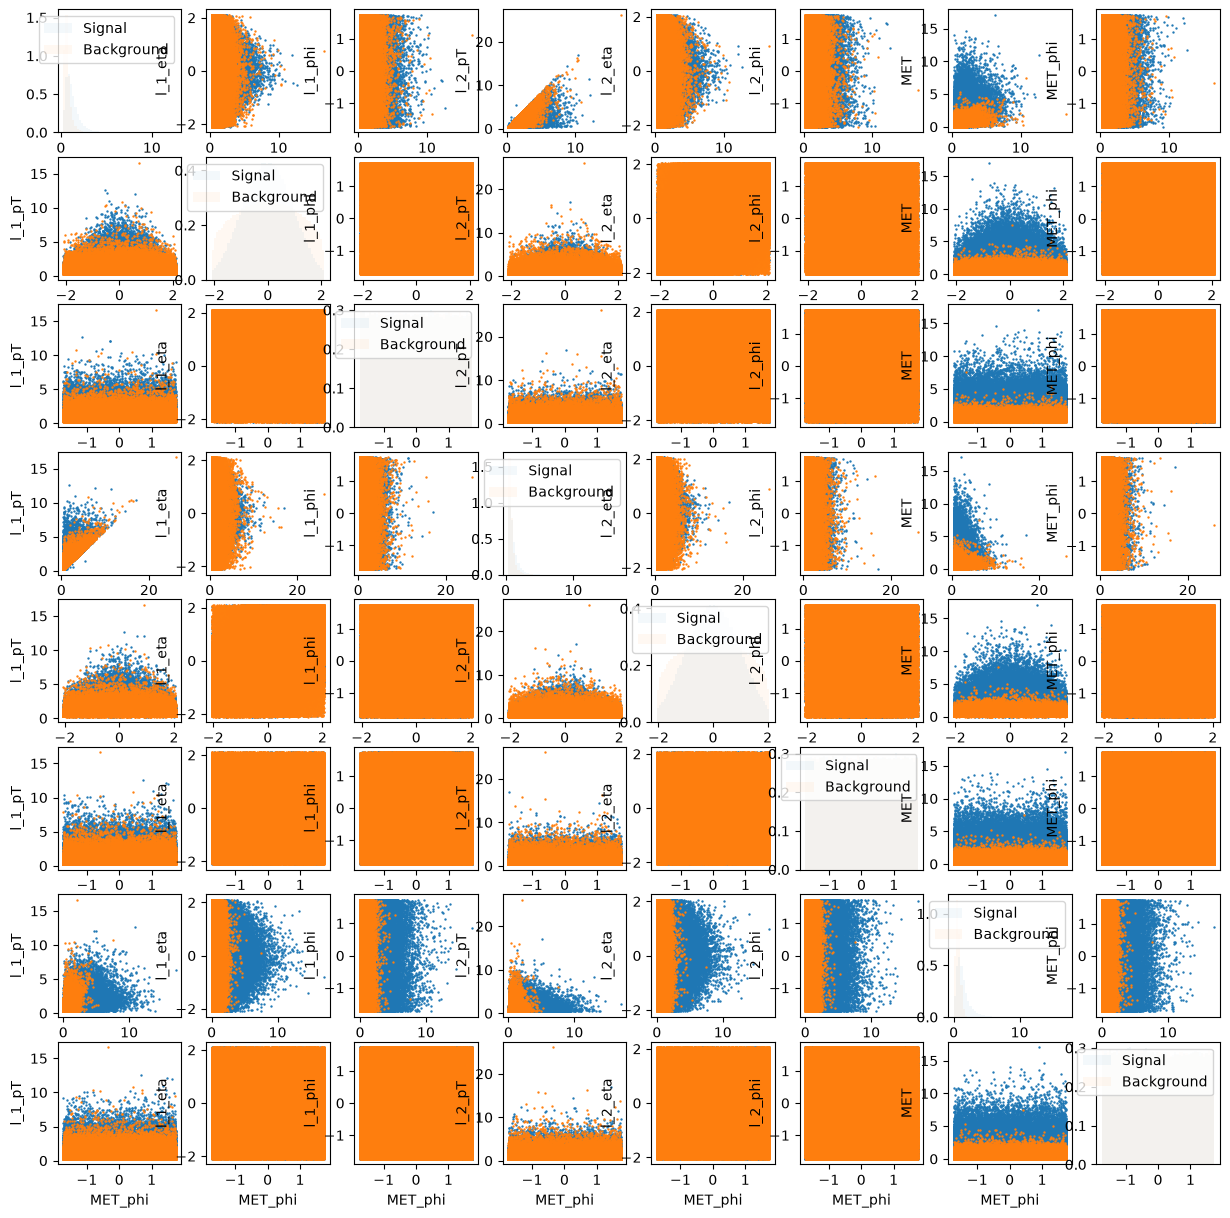

In [38]:
# part b
df_sample = df.sample(n=10000, random_state=42)
columns = df_sample.columns[1:9]
n_columns=len(columns)
plt.figure(figsize=(15,15))

plot_i=0
for i,x_var_name in enumerate(columns):
    for j,y_var_name in enumerate(columns):
        plot_i+=1
        plt.subplot(n_columns,n_columns,plot_i)
        make_legend = plot_i==1
        if i==j:
            compare_distributions(df,x_var_name,
                     selection_dict,
                     alpha=0.05,
                     density=1,
                     bins=50,
                     )
        else:
            compare_scatter(df,x_var_name,y_var_name,selection_dict,make_legend=make_legend)

# part c
It looks like the MET_phi and l_1_pT variables are the best for separating signal from background

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [22]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [41]:
#part b
# covariance matrix
cov = np.cov(df[VarNames[1:]].to_numpy(), rowvar = False)
print(cov)

[[ 4.67481925e-01 -3.96674207e-04  7.66214265e-05  3.05037988e-01
  -3.48826988e-04  7.37336647e-04  2.28434336e-01 -9.36714374e-04
   9.75240349e-02 -9.73253567e-03  3.64432455e-01  2.87223483e-01
  -5.97024601e-02 -1.23988205e-02  3.42587023e-01  9.77389248e-02
  -4.69491360e-02  2.21632465e-02]
 [-3.96674207e-04  1.00430144e+00 -8.57630732e-04 -1.62905654e-04
   4.08312894e-01 -1.04201049e-03 -2.14697798e-03 -5.88968323e-04
  -1.37057212e-03 -1.10889241e-03 -5.53826632e-04 -6.68920291e-04
   3.01299870e-04  4.27122683e-04 -6.04009571e-04 -9.87471350e-04
  -7.40330277e-04  3.21632240e-04]
 [ 7.66214265e-05 -8.57630732e-04  1.00397336e+00  1.31296001e-03
   2.50714928e-04 -2.66810178e-01  7.66365893e-04 -1.84803977e-01
   7.06206018e-04 -1.87269105e-03  1.06306621e-03  8.68782730e-04
   2.01595554e-04  1.06029189e-03  1.46376567e-03  9.01233064e-04
   9.94305740e-04  2.59098396e-04]
 [ 3.05037988e-01 -1.62905654e-04  1.31296001e-03  4.25490163e-01
  -5.75571383e-04  1.55883996e-04  7.

In [42]:
corr = np.corrcoef(df[VarNames[1:]].to_numpy(), rowvar = False)
print(corr)

[[ 1.00000000e+00 -5.78921273e-04  1.11842464e-04  6.83953780e-01
  -5.08594430e-04  1.07636651e-03  3.82675470e-01 -1.36774936e-03
   1.60428419e-01 -1.41964506e-02  8.51136209e-01  7.22753542e-01
  -1.85501073e-01 -2.11139596e-02  8.10678230e-01  2.29308652e-01
  -1.57453882e-01  1.64500727e-01]
 [-5.78921273e-04  1.00000000e+00 -8.54097003e-04 -2.49206493e-04
   4.06167328e-01 -1.03780753e-03 -2.45384543e-03 -5.86734524e-04
  -1.53823223e-03 -1.10355390e-03 -8.82482751e-04 -1.14840487e-03
   6.38709703e-04  4.96240629e-04 -9.75150826e-04 -1.58062104e-03
  -1.69395415e-03  1.62871235e-03]
 [ 1.11842464e-04 -8.54097003e-04  1.00000000e+00  2.00884136e-03
   2.49438239e-04 -2.65777410e-01  8.76045628e-04 -1.84133143e-01
   7.92724671e-04 -1.86397989e-03  1.69419599e-03  1.49177313e-03
   4.27421600e-04  1.23207194e-03  2.36358093e-03  1.44281722e-03
   2.27544861e-03  1.31226180e-03]
 [ 6.83953780e-01 -2.49206493e-04  2.00884136e-03  1.00000000e+00
  -8.79626621e-04  2.38524797e-04  1.

In [43]:
# low level
cov_low = np.cov(df[RawNames], rowvar = False)
corr_low = np.corrcoef(df[RawNames], rowvar = False)
print(f"Low Level Covarriance Matrix: {cov_low}, \n Low Level Correlation Matrix {corr_low}")

Low Level Covarriance Matrix: [[ 4.67481925e-01 -3.96674207e-04  7.66214265e-05  3.05037988e-01
  -3.48826988e-04  7.37336647e-04  2.28434336e-01 -9.36714374e-04]
 [-3.96674207e-04  1.00430144e+00 -8.57630732e-04 -1.62905654e-04
   4.08312894e-01 -1.04201049e-03 -2.14697798e-03 -5.88968323e-04]
 [ 7.66214265e-05 -8.57630732e-04  1.00397336e+00  1.31296001e-03
   2.50714928e-04 -2.66810178e-01  7.66365893e-04 -1.84803977e-01]
 [ 3.05037988e-01 -1.62905654e-04  1.31296001e-03  4.25490163e-01
  -5.75571383e-04  1.55883996e-04  7.94518800e-02 -1.56177040e-03]
 [-3.48826988e-04  4.08312894e-01  2.50714928e-04 -5.75571383e-04
   1.00626446e+00  4.41588261e-04  3.81652056e-04 -3.22449476e-04]
 [ 7.37336647e-04 -1.04201049e-03 -2.66810178e-01  1.55883996e-04
   4.41588261e-04  1.00379832e+00 -3.03975643e-04 -3.54343031e-02]
 [ 2.28434336e-01 -2.14697798e-03  7.66365893e-04  7.94518800e-02
   3.81652056e-04 -3.03975643e-04  7.62248700e-01 -2.79212918e-03]
 [-9.36714374e-04 -5.88968323e-04 -1.84

In [44]:
# high level
cov_high = np.cov(df[FeatureNames], rowvar = False)
corr_high = np.corrcoef(df[FeatureNames], rowvar = False)
print(f"High Level Covarriance Matrix: {cov_high}, \n High Level Correlation Matrix {corr_high}")

High Level Covarriance Matrix: [[ 0.19018823  0.05813297  0.08709136  0.1464394  -0.00345651 -0.02511279
   0.00908347  0.04224066 -0.02896168  0.02089723]
 [ 0.05813297  0.33782719  0.10401425  0.30199264  0.2281247  -0.18501679
   0.05166586  0.24186516  0.20987467  0.18916951]
 [ 0.08709136  0.10401425  0.22157807  0.24882357 -0.08335872 -0.18090014
   0.05816081  0.16548304 -0.11290414  0.23210005]
 [ 0.1464394   0.30199264  0.24882357  0.79048911  0.08231538 -0.1198512
   0.05531787  0.41474304  0.04368455  0.40877889]
 [-0.00345651  0.2281247  -0.08335872  0.08231538  0.38201461 -0.04138282
  -0.0103629   0.0957808   0.37976344 -0.01103752]
 [-0.02511279 -0.18501679 -0.18090014 -0.1198512  -0.04138282  1.00537396
  -0.05373485 -0.23307398  0.01713455 -0.46099861]
 [ 0.00908347  0.05166586  0.05816081  0.05531787 -0.0103629  -0.05373485
   0.0388299   0.03920886 -0.01434118  0.04462891]
 [ 0.04224066  0.24186516  0.16548304  0.41474304  0.0957808  -0.23307398
   0.03920886  0.3886

In [49]:
display(HTML(tabulate.tabulate(cov, tablefmt='html', headers=VarNames[1:], showindex=VarNames[1:])))
display(HTML(tabulate.tabulate(corr, tablefmt='html', headers=VarNames[1:], showindex=VarNames[1:])))
display(HTML(tabulate.tabulate(cov_low, tablefmt='html', headers=RawNames, showindex=RawNames)))
display(HTML(tabulate.tabulate(corr_low, tablefmt='html', headers=RawNames, showindex=RawNames)))
display(HTML(tabulate.tabulate(cov_high, tablefmt='html', headers=FeatureNames, showindex=FeatureNames)))
display(HTML(tabulate.tabulate(corr_high, tablefmt='html', headers=FeatureNames, showindex=FeatureNames)))

,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467482,-0.000396674,7.66214e-05,0.305038,-0.000348827,0.000737337,0.228434,-0.000936714,0.097524,-0.00973254,0.364432,0.287223,-0.0597025,-0.0123988,0.342587,0.0977389,-0.0469491,0.0221632
l_1_eta,-0.000396674,1.0043,-0.000857631,-0.000162906,0.408313,-0.00104201,-0.00214698,-0.000588968,-0.00137057,-0.00110889,-0.000553827,-0.00066892,0.0003013,0.000427123,-0.00060401,-0.000987471,-0.00074033,0.000321632
l_1_phi,7.66214e-05,-0.000857631,1.00397,0.00131296,0.000250715,-0.26681,0.000766366,-0.184804,0.000706206,-0.00187269,0.00106307,0.000868783,0.000201596,0.00106029,0.00146377,0.000901233,0.000994306,0.000259098
l_2_pT,0.305038,-0.000162906,0.00131296,0.42549,-0.000575571,0.000155884,0.0794519,-0.00156177,-0.000533893,0.0513299,0.325434,0.162941,-0.0993511,-0.0688858,0.32194,0.00571563,-0.00383465,-0.0279102
l_2_eta,-0.000348827,0.408313,0.000250715,-0.000575571,1.00626,0.000441588,0.000381652,-0.000322449,0.00108429,-0.000756451,-0.000607671,1.88755e-05,0.000320625,0.00139889,-0.000678582,0.000670436,-0.000306871,0.000296341
l_2_phi,0.000737337,-0.00104201,-0.26681,0.000155884,0.000441588,1.0038,-0.000303976,-0.0354343,0.00144703,-0.0018005,0.000759915,0.00050892,0.000551145,0.00225915,0.000906438,0.0013266,-0.000241209,3.70399e-05
MET,0.228434,-0.00214698,0.000766366,0.0794519,0.000381652,-0.000303976,0.762249,-0.00279213,0.546481,0.153956,0.144522,0.365194,0.187912,0.154785,0.165543,0.315143,0.145682,0.0730924
MET_phi,-0.000936714,-0.000588968,-0.184804,-0.00156177,-0.000322449,-0.0354343,-0.00279213,1.00331,-0.0048952,-0.000441791,-0.00148315,-0.001201,-0.00022953,8.38685e-05,-0.00170675,-0.000569851,-0.00170906,0.000119405
MET_rel,0.097524,-0.00137057,0.000706206,-0.000533893,0.00108429,0.00144703,0.546481,-0.0048952,0.790489,-0.119851,0.0436845,0.301993,0.248824,0.408779,0.0823154,0.414743,0.146439,0.0553179
axial_MET,-0.00973254,-0.00110889,-0.00187269,0.0513299,-0.000756451,-0.0018005,0.153956,-0.000441791,-0.119851,1.00537,0.0171346,-0.185017,-0.1809,-0.460999,-0.0413828,-0.233074,-0.0251128,-0.0537349


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.000578921,0.000111842,0.683954,-0.000508594,0.00107637,0.382675,-0.00136775,0.160428,-0.0141965,0.851136,0.722754,-0.185501,-0.021114,0.810678,0.229309,-0.157454,0.164501
l_1_eta,-0.000578921,1,-0.000854097,-0.000249206,0.406167,-0.00103781,-0.00245385,-0.000586735,-0.00153823,-0.00110355,-0.000882483,-0.0011484,0.00063871,0.000496241,-0.000975151,-0.00158062,-0.00169395,0.00162871
l_1_phi,0.000111842,-0.000854097,1,0.00200884,0.000249438,-0.265777,0.000876046,-0.184133,0.000792725,-0.00186398,0.0016942,0.00149177,0.000427422,0.00123207,0.00236358,0.00144282,0.00227545,0.00131226
l_2_pT,0.683954,-0.000249206,0.00200884,1,-0.000879627,0.000238525,0.139512,-0.00239031,-0.000920581,0.0784805,0.796679,0.429772,-0.323567,-0.122958,0.798528,0.0140558,-0.01348,-0.217138
l_2_eta,-0.000508594,0.406167,0.000249438,-0.000879627,1,0.000439378,0.000435776,-0.000320913,0.00121574,-0.000752075,-0.000967334,3.2374e-05,0.000679012,0.00162368,-0.00109448,0.0010721,-0.000701469,0.00149917
l_2_phi,0.00107637,-0.00103781,-0.265777,0.000238525,0.000439378,1,-0.00034751,-0.0353088,0.00162445,-0.00179228,0.00121117,0.000873935,0.00116864,0.00262539,0.00146378,0.00212398,-0.000552051,0.000187613
MET,0.382675,-0.00245385,0.000876046,0.139512,0.000435776,-0.00034751,1,-0.00319278,0.70401,0.175867,0.264332,0.719661,0.457239,0.20642,0.306776,0.579022,0.382618,0.424855
MET_phi,-0.00136775,-0.000586735,-0.184133,-0.00239031,-0.000320913,-0.0353088,-0.00319278,1,-0.00549673,-0.000439881,-0.00236446,-0.0020629,-0.000486809,9.74883e-05,-0.00275684,-0.000912596,-0.00391244,0.000604952
MET_rel,0.160428,-0.00153823,0.000792725,-0.000920581,0.00121574,0.00162445,0.70401,-0.00549673,1,-0.134441,0.0784593,0.584388,0.594539,0.535318,0.149794,0.748284,0.377675,0.315743
axial_MET,-0.0141965,-0.00110355,-0.00186398,0.0784805,-0.000752075,-0.00179228,0.175867,-0.000439881,-0.134441,1,0.0272881,-0.317468,-0.383276,-0.535313,-0.0667754,-0.372877,-0.0574301,-0.271963


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467482,-0.000396674,7.66214e-05,0.305038,-0.000348827,0.000737337,0.228434,-0.000936714
l_1_eta,-0.000396674,1.0043,-0.000857631,-0.000162906,0.408313,-0.00104201,-0.00214698,-0.000588968
l_1_phi,7.66214e-05,-0.000857631,1.00397,0.00131296,0.000250715,-0.26681,0.000766366,-0.184804
l_2_pT,0.305038,-0.000162906,0.00131296,0.42549,-0.000575571,0.000155884,0.0794519,-0.00156177
l_2_eta,-0.000348827,0.408313,0.000250715,-0.000575571,1.00626,0.000441588,0.000381652,-0.000322449
l_2_phi,0.000737337,-0.00104201,-0.26681,0.000155884,0.000441588,1.0038,-0.000303976,-0.0354343
MET,0.228434,-0.00214698,0.000766366,0.0794519,0.000381652,-0.000303976,0.762249,-0.00279213
MET_phi,-0.000936714,-0.000588968,-0.184804,-0.00156177,-0.000322449,-0.0354343,-0.00279213,1.00331


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.000578921,0.000111842,0.683954,-0.000508594,0.00107637,0.382675,-0.00136775
l_1_eta,-0.000578921,1,-0.000854097,-0.000249206,0.406167,-0.00103781,-0.00245385,-0.000586735
l_1_phi,0.000111842,-0.000854097,1,0.00200884,0.000249438,-0.265777,0.000876046,-0.184133
l_2_pT,0.683954,-0.000249206,0.00200884,1,-0.000879627,0.000238525,0.139512,-0.00239031
l_2_eta,-0.000508594,0.406167,0.000249438,-0.000879627,1,0.000439378,0.000435776,-0.000320913
l_2_phi,0.00107637,-0.00103781,-0.265777,0.000238525,0.000439378,1,-0.00034751,-0.0353088
MET,0.382675,-0.00245385,0.000876046,0.139512,0.000435776,-0.00034751,1,-0.00319278
MET_phi,-0.00136775,-0.000586735,-0.184133,-0.00239031,-0.000320913,-0.0353088,-0.00319278,1


,dPhi_r_b,M_TR_2,R,MET_rel,S_R,axial_MET,cos_theta_r1,M_Delta_R,M_R,MT2
dPhi_r_b,0.190188,0.058133,0.0870914,0.146439,-0.00345651,-0.0251128,0.00908347,0.0422407,-0.0289617,0.0208972
M_TR_2,0.058133,0.337827,0.104014,0.301993,0.228125,-0.185017,0.0516659,0.241865,0.209875,0.18917
R,0.0870914,0.104014,0.221578,0.248824,-0.0833587,-0.1809,0.0581608,0.165483,-0.112904,0.2321
MET_rel,0.146439,0.301993,0.248824,0.790489,0.0823154,-0.119851,0.0553179,0.414743,0.0436845,0.408779
S_R,-0.00345651,0.228125,-0.0833587,0.0823154,0.382015,-0.0413828,-0.0103629,0.0957808,0.379763,-0.0110375
axial_MET,-0.0251128,-0.185017,-0.1809,-0.119851,-0.0413828,1.00537,-0.0537349,-0.233074,0.0171346,-0.460999
cos_theta_r1,0.00908347,0.0516659,0.0581608,0.0553179,-0.0103629,-0.0537349,0.0388299,0.0392089,-0.0143412,0.0446289
M_Delta_R,0.0422407,0.241865,0.165483,0.414743,0.0957808,-0.233074,0.0392089,0.388624,0.07393,0.432897
M_R,-0.0289617,0.209875,-0.112904,0.0436845,0.379763,0.0171346,-0.0143412,0.07393,0.392167,-0.0365444
MT2,0.0208972,0.18917,0.2321,0.408779,-0.0110375,-0.460999,0.0446289,0.432897,-0.0365444,0.737661


,dPhi_r_b,M_TR_2,R,MET_rel,S_R,axial_MET,cos_theta_r1,M_Delta_R,M_R,MT2
dPhi_r_b,1,0.229342,0.424248,0.377675,-0.0128235,-0.0574301,0.1057,0.155372,-0.106046,0.0557916
M_TR_2,0.229342,1,0.380174,0.584388,0.635017,-0.317468,0.4511,0.667515,0.576603,0.378944
R,0.424248,0.380174,1,0.594539,-0.286515,-0.383276,0.627024,0.56393,-0.383011,0.574095
MET_rel,0.377675,0.584388,0.594539,1,0.149794,-0.134441,0.315743,0.748284,0.0784593,0.535318
S_R,-0.0128235,0.635017,-0.286515,0.149794,1,-0.0667754,-0.085086,0.248584,0.981155,-0.0207923
axial_MET,-0.0574301,-0.317468,-0.383276,-0.134441,-0.0667754,1,-0.271963,-0.372877,0.0272881,-0.535313
cos_theta_r1,0.1057,0.4511,0.627024,0.315743,-0.085086,-0.271963,1,0.31918,-0.116216,0.263697
M_Delta_R,0.155372,0.667515,0.56393,0.748284,0.248584,-0.372877,0.31918,1,0.189374,0.808521
M_R,-0.106046,0.576603,-0.383011,0.0784593,0.981155,0.0272881,-0.116216,0.189374,1,-0.0679449
MT2,0.0557916,0.378944,0.574095,0.535318,-0.0207923,-0.535313,0.263697,0.808521,-0.0679449,1


In [56]:
def tab_matrices(df, rowdiv):
    import tabulate
    whole = df.iloc[:, 1:]
    low = df.iloc[:, 1:rowdiv]
    high = df.iloc[:, rowdiv:]

    cov_whole = np.cov(whole.to_numpy(), rowvar=False)
    corr_whole = np.corrcoef(whole.to_numpy(), rowvar=False)
    cov_low = np.cov(low.to_numpy(), rowvar=False)
    corr_low = np.corrcoef(low.to_numpy(), rowvar=False)
    cov_high = np.cov(high.to_numpy(), rowvar=False)
    corr_high = np.corrcoef(high.to_numpy(), rowvar=False)

    matrices = [
        ("Whole Covariance", cov_whole, whole.columns),
        ("Whole Correlation", corr_whole, whole.columns),
        ("Low-Level Covariance", cov_low, low.columns),
        ("Low-Level Correlation", corr_low, low.columns),
        ("High-Level Covariance", cov_high, high.columns),
        ("High-Level Correlation", corr_high, high.columns)
    ]
    for name, matrix, labels in matrices:
        print(name)
        display(HTML(tabulate.tabulate(
            matrix,
            headers=list(labels),
            showindex=list(labels),
            tablefmt="html",
            floatfmt=".3f"
        )))

In [57]:
tab_matrices(df, 9)

Whole Covariance


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000,0.000,0.305,-0.000,0.001,0.228,-0.001,0.098,-0.010,0.364,0.287,-0.060,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0.000,1.004,-0.001,-0.000,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0.000,0.000,-0.001,-0.001,-0.001,0.000
l_1_phi,0.000,-0.001,1.004,0.001,0.000,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0.000,0.001,0.001,0.001,0.001,0.000
l_2_pT,0.305,-0.000,0.001,0.425,-0.001,0.000,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0.000,0.408,0.000,-0.001,1.006,0.000,0.000,-0.000,0.001,-0.001,-0.001,0.000,0.000,0.001,-0.001,0.001,-0.000,0.000
l_2_phi,0.001,-0.001,-0.267,0.000,0.000,1.004,-0.000,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0.000,0.000
MET,0.228,-0.002,0.001,0.079,0.000,-0.000,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0.000,-0.035,-0.003,1.003,-0.005,-0.000,-0.001,-0.001,-0.000,0.000,-0.002,-0.001,-0.002,0.000
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.790,-0.120,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.010,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0.000,-0.120,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


Whole Correlation


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1.000,-0.001,0.000,0.684,-0.001,0.001,0.383,-0.001,0.160,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1.000,-0.001,-0.000,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0.000,-0.001,-0.002,-0.002,0.002
l_1_phi,0.000,-0.001,1.000,0.002,0.000,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0.000,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0.000,0.002,1.000,-0.001,0.000,0.140,-0.002,-0.001,0.078,0.797,0.430,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0.000,-0.001,1.000,0.000,0.000,-0.000,0.001,-0.001,-0.001,0.000,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0.000,0.000,1.000,-0.000,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0.000
MET,0.383,-0.002,0.001,0.140,0.000,-0.000,1.000,-0.003,0.704,0.176,0.264,0.720,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0.000,-0.035,-0.003,1.000,-0.005,-0.000,-0.002,-0.002,-0.000,0.000,-0.003,-0.001,-0.004,0.001
MET_rel,0.160,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1.000,-0.134,0.078,0.584,0.595,0.535,0.150,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0.000,-0.134,1.000,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


Low-Level Covariance


...

,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1.000,-0.001,0.000,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1.000,-0.001,-0.000,0.406,-0.001,-0.002,-0.001
l_1_phi,0.000,-0.001,1.000,0.002,0.000,-0.266,0.001,-0.184
l_2_pT,0.684,-0.000,0.002,1.000,-0.001,0.000,0.140,-0.002
l_2_eta,-0.001,0.406,0.000,-0.001,1.000,0.000,0.000,-0.000
l_2_phi,0.001,-0.001,-0.266,0.000,0.000,1.000,-0.000,-0.035
MET,0.383,-0.002,0.001,0.140,0.000,-0.000,1.000,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0.000,-0.035,-0.003,1.000


High-Level Covariance


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.790,-0.120,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.120,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054
M_R,0.044,0.017,0.392,0.210,-0.113,-0.037,0.380,0.074,-0.029,-0.014
M_TR_2,0.302,-0.185,0.210,0.338,0.104,0.189,0.228,0.242,0.058,0.052
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.083,0.165,0.087,0.058
MT2,0.409,-0.461,-0.037,0.189,0.232,0.738,-0.011,0.433,0.021,0.045
S_R,0.082,-0.041,0.380,0.228,-0.083,-0.011,0.382,0.096,-0.003,-0.010
M_Delta_R,0.415,-0.233,0.074,0.242,0.165,0.433,0.096,0.389,0.042,0.039
dPhi_r_b,0.146,-0.025,-0.029,0.058,0.087,0.021,-0.003,0.042,0.190,0.009
cos_theta_r1,0.055,-0.054,-0.014,0.052,0.058,0.045,-0.010,0.039,0.009,0.039


High-Level Correlation


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1.000,-0.134,0.078,0.584,0.595,0.535,0.150,0.748,0.378,0.316
axial_MET,-0.134,1.000,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272
M_R,0.078,0.027,1.000,0.577,-0.383,-0.068,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1.000,0.380,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.380,1.000,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.068,0.379,0.574,1.000,-0.021,0.809,0.056,0.264
S_R,0.150,-0.067,0.981,0.635,-0.287,-0.021,1.000,0.249,-0.013,-0.085
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1.000,0.155,0.319
dPhi_r_b,0.378,-0.057,-0.106,0.229,0.424,0.056,-0.013,0.155,1.000,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.085,0.319,0.106,1.000


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

# Part a
- 'l_1_pT' - $x > x_c$
- 'l_1_eta' - $|x - \mu| < x_c$
- 'l_1_phi' - No useful cut
- 'l_2_pT' - $x > x_c$
- 'l_2_eta' - $|x - \mu| < x_c$
- 'l_2_phi' - No useful cut
- 'MET' - $x > x_c$
- 'MET_phi' - No useful cut
- 'MT2' - $x > x_c$
- 'axial_MET' - $|x - \mu| >x_c$
- 'MET_rel' - $x > x_c$
- 'S_R' - $x > x_c$
- 'cos_theta_r1' - $x > x_c$
- 'M_TR_2' - $x > x_c$
- 'R' - $x > x_c$
- 'M_Delta_R' - $x > x_c$
- 'M_R' - $x >x_c$
- 'dPhi_r_b' - $x > x_c$

In [25]:
# Exercise 5.2
def efficiencies(df_sig, df_bkg, var, thresholds):
    tpr = []
    fpr = []

    for xc in thresholds:
        sig_pass = (df_sig[var] > xc).sum()
        bkg_pass = (df_bkg[var] > xc).sum()

        tpr.append(sig_pass / len(df_sig))
        fpr.append(bkg_pass / len(df_bkg))

    return tpr, fpr

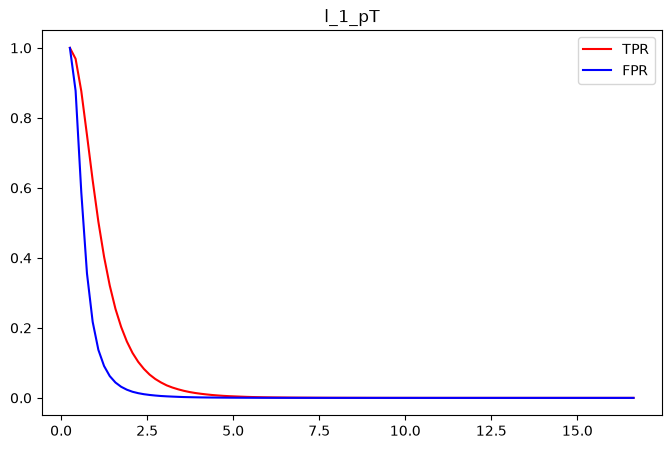

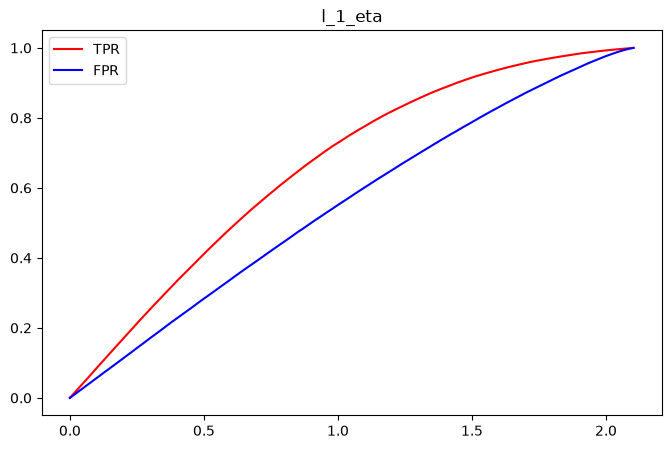

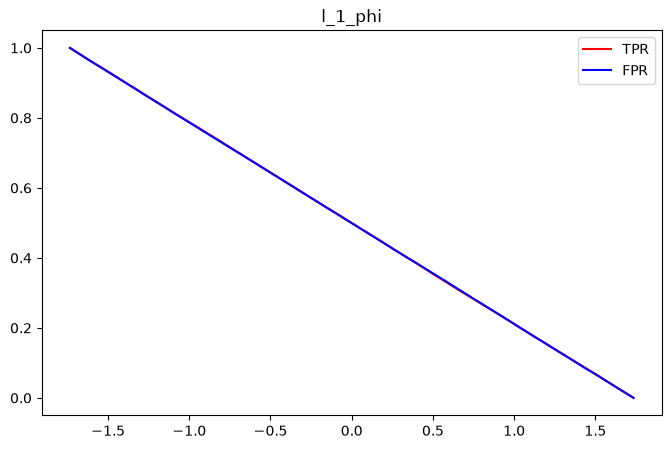

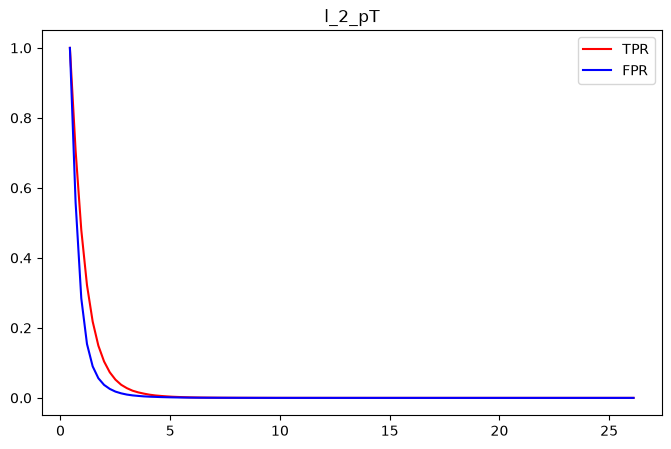

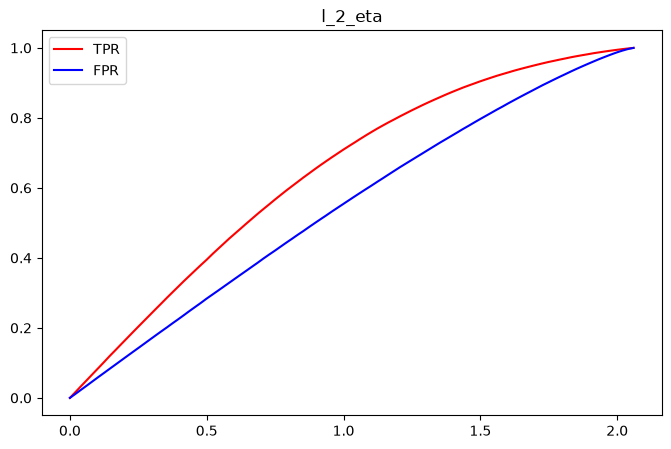

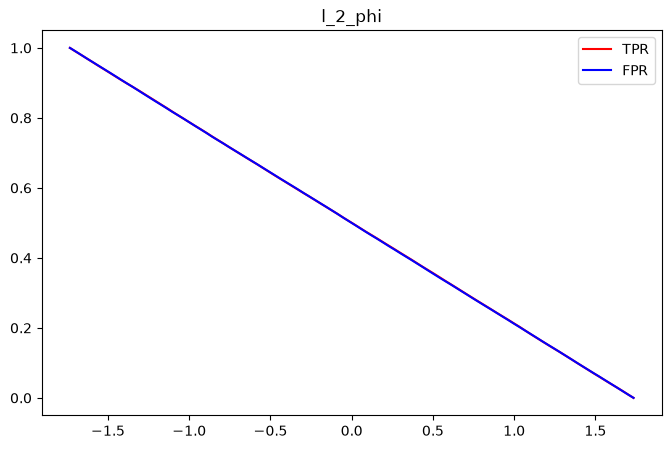

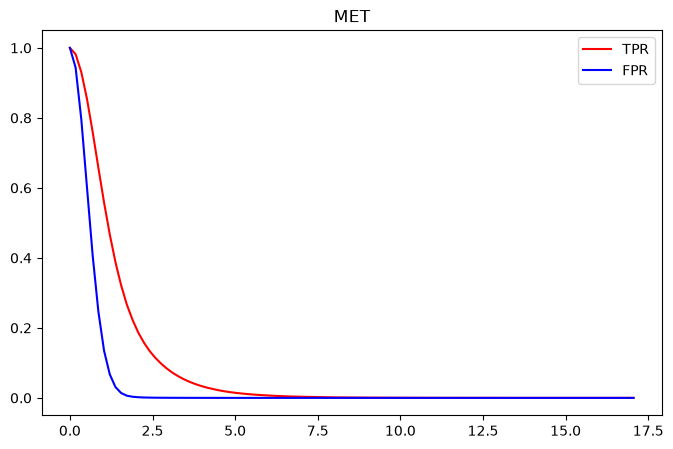

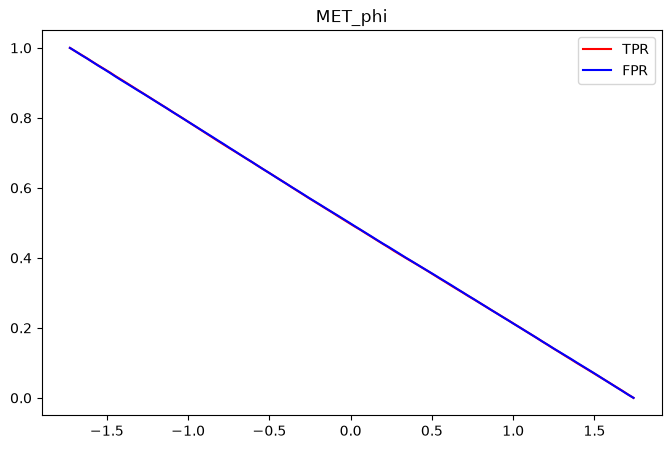

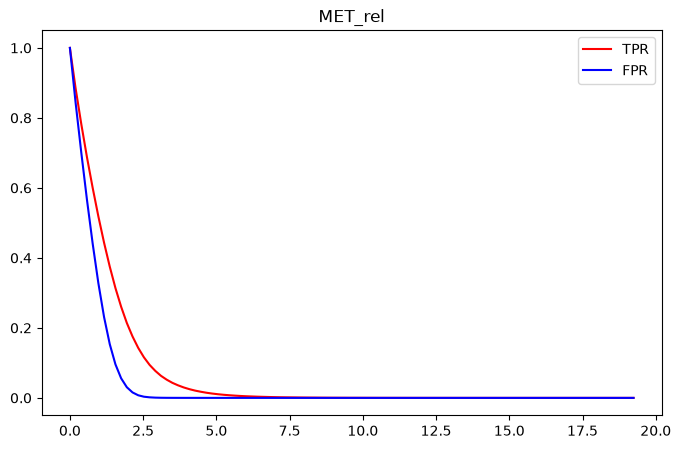

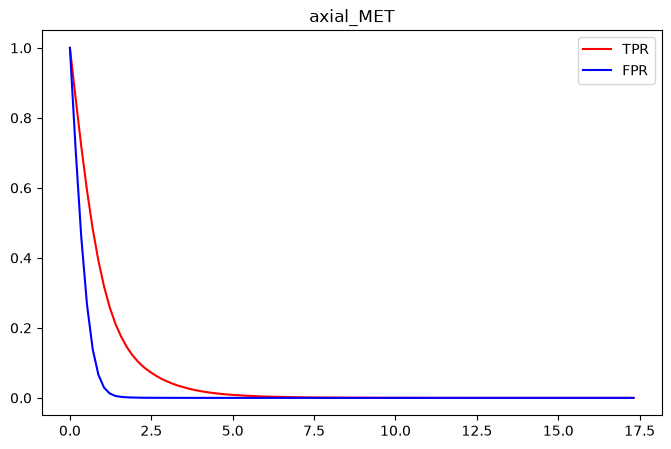

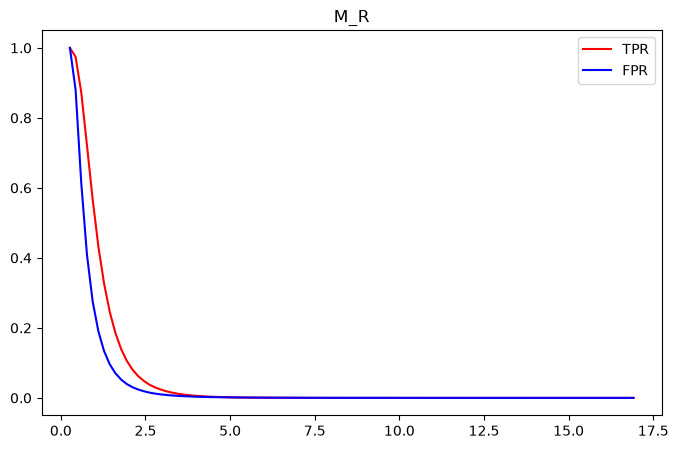

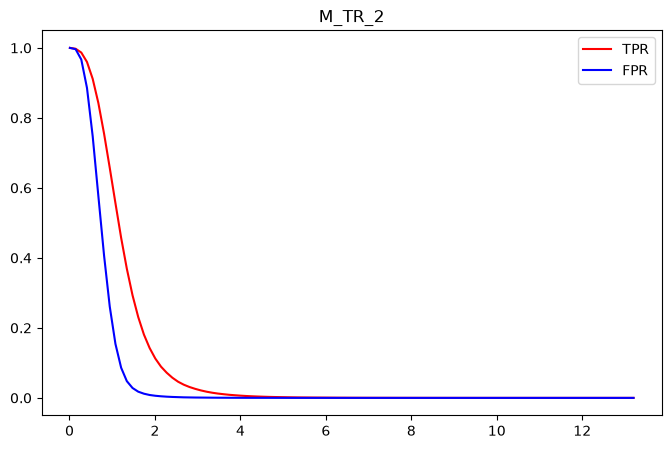

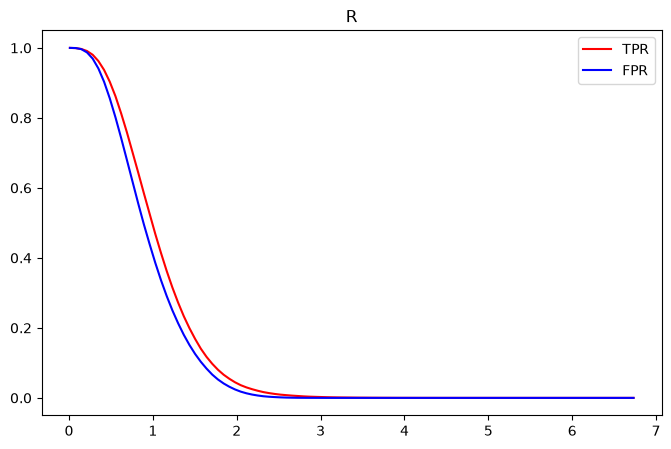

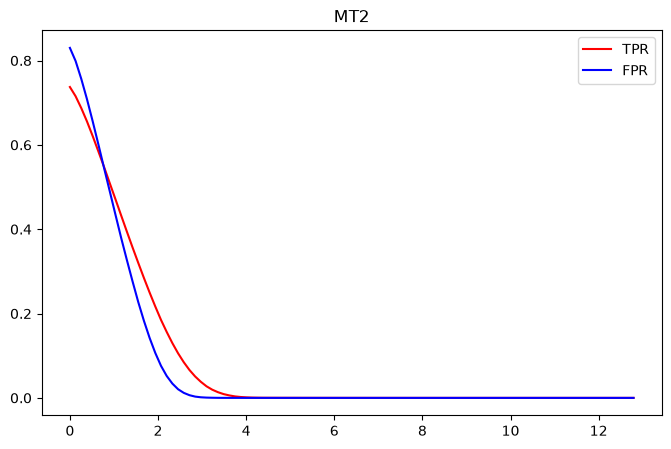

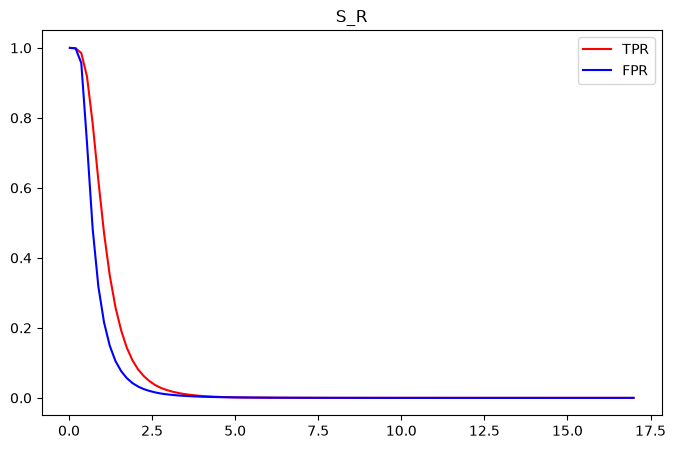

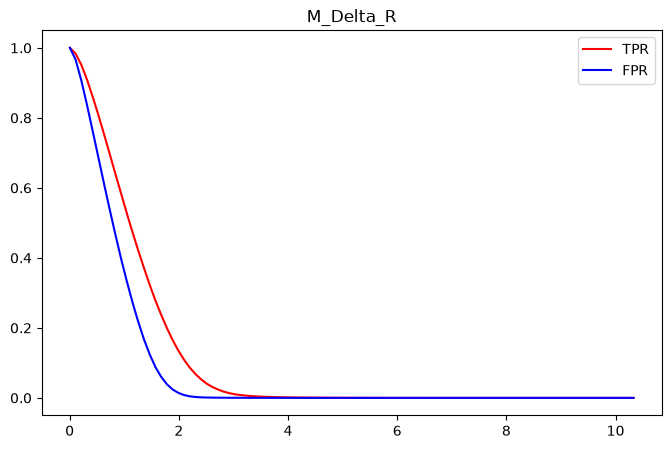

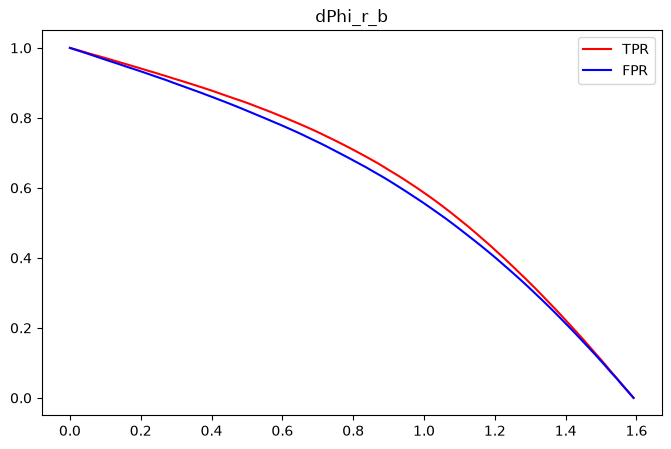

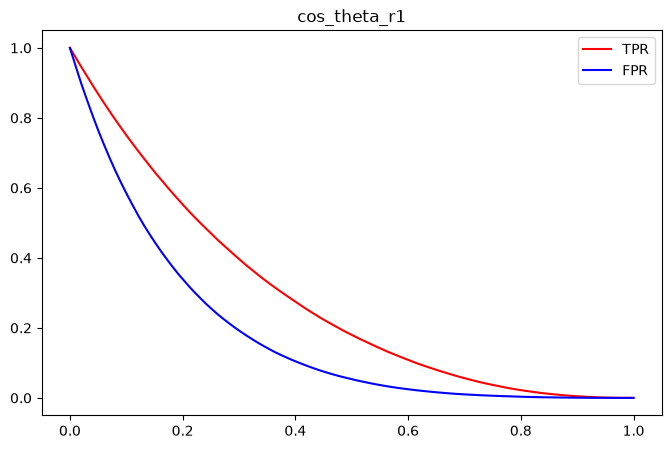

In [29]:
def efficiencies(df_sig, df_bkg, var, thresholds, selection):
    tpr = []
    fpr = []

    for xc in thresholds:
        if selection == ">":
            sig_pass = (df_sig[var] > xc).sum()
            bkg_pass = (df_bkg[var] > xc).sum()

        elif selection == "<":
            sig_pass = (df_sig[var] < xc).sum()
            bkg_pass = (df_bkg[var] < xc).sum()

        elif selection == "abs>":
            sig_pass = (abs(df_sig[var]) > xc).sum()
            bkg_pass = (abs(df_bkg[var]) > xc).sum()

        elif selection == "abs<":
            sig_pass = (abs(df_sig[var]) < xc).sum()
            bkg_pass = (abs(df_bkg[var]) < xc).sum()

        tpr.append(sig_pass / len(df_sig))
        fpr.append(bkg_pass / len(df_bkg))

    return tpr, fpr


selections = {
    "l_1_pT": ">",
    "l_1_eta": "abs<",
    "l_1_phi": ">",
    "l_2_pT": ">",
    "l_2_eta": "abs<",
    "l_2_phi": ">",
    "MET": ">",
    "MET_phi": ">",
    "MET_rel": ">",
    "axial_MET": "abs>",
    "M_R": ">",
    "M_TR_2": ">",
    "R": ">",
    "MT2": ">",
    "S_R": ">",
    "M_Delta_R": ">",
    "dPhi_r_b": ">",
    "cos_theta_r1": ">"
}

for var in VarNames[1:]:
    selection = selections[var]

    if selection.startswith("abs"):
        thresholds = np.linspace(0, df[var].abs().max(), 100)
    else:
        thresholds = np.linspace(df[var].min(), df[var].max(), 100)

    tpr, fpr = efficiencies(df_sig, df_bkg, var, thresholds, selection)

    plt.figure(figsize=(8, 5))
    plt.plot(thresholds, tpr, label="TPR", color="red")
    plt.plot(thresholds, fpr, label="FPR", color="blue")

    plt.title(var)
    plt.legend()
    plt.show()

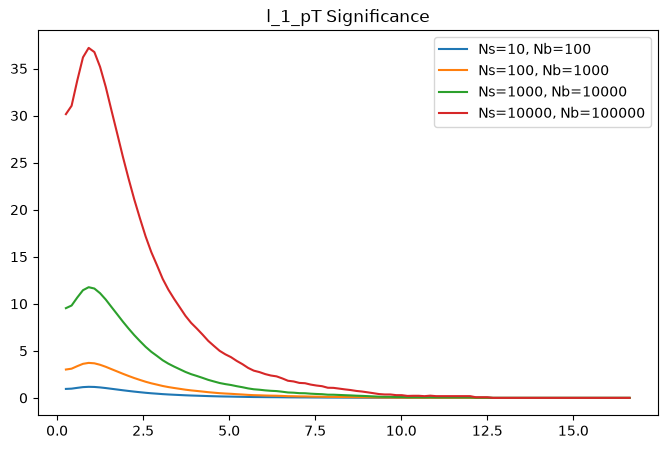

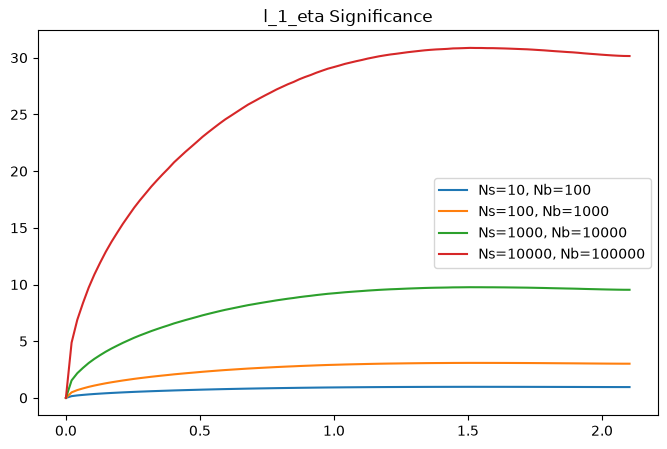

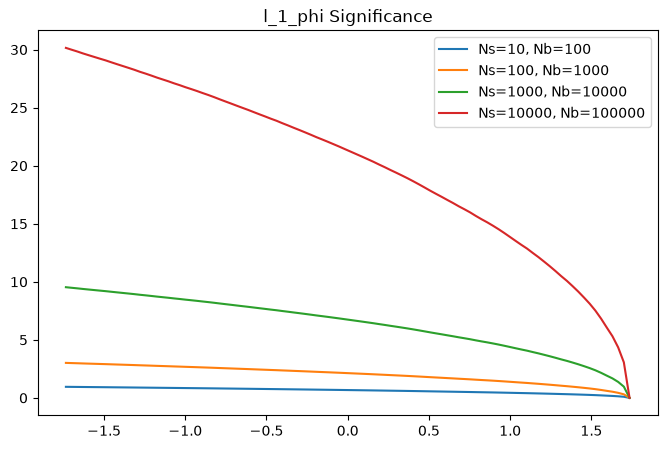

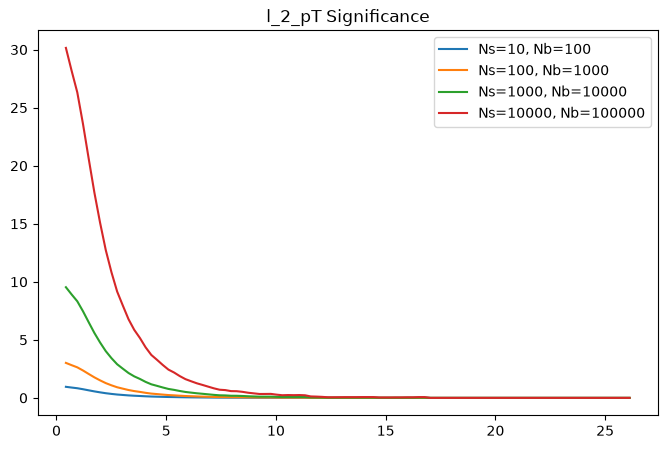

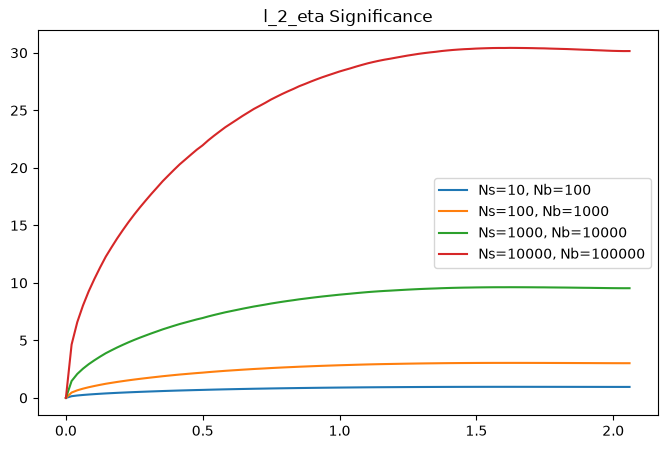

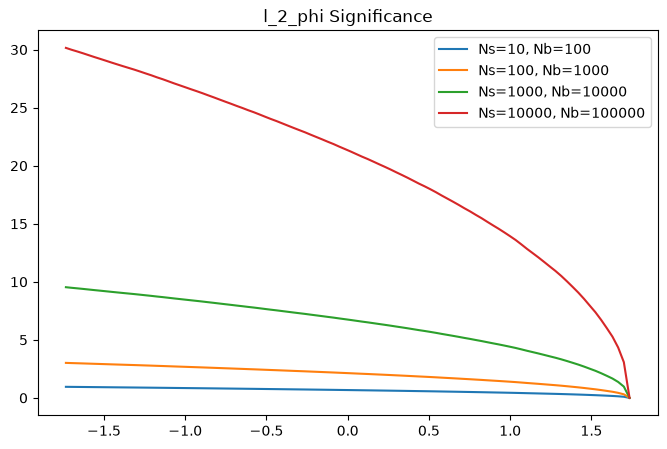

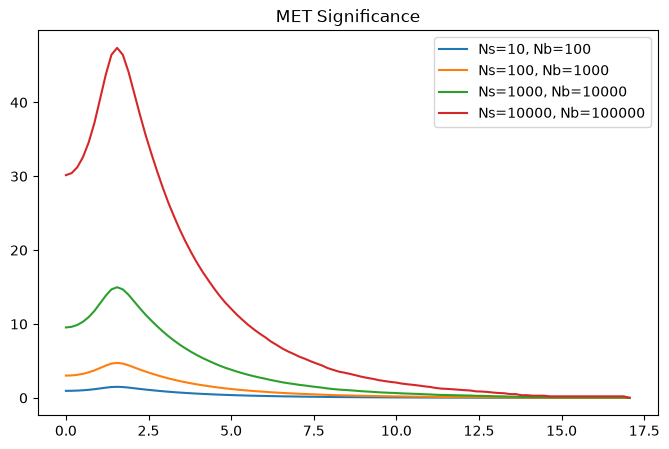

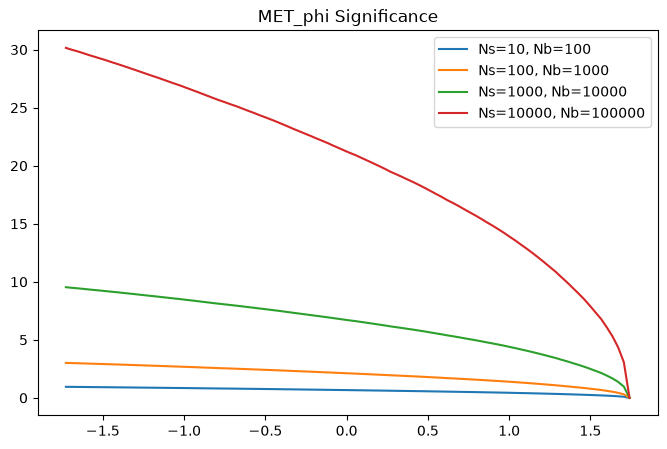

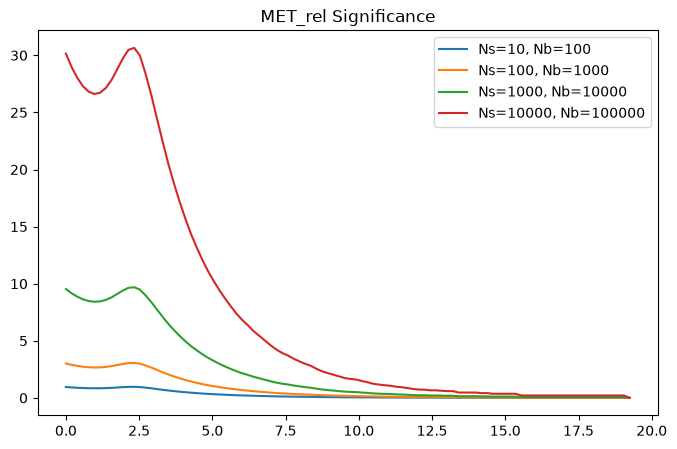

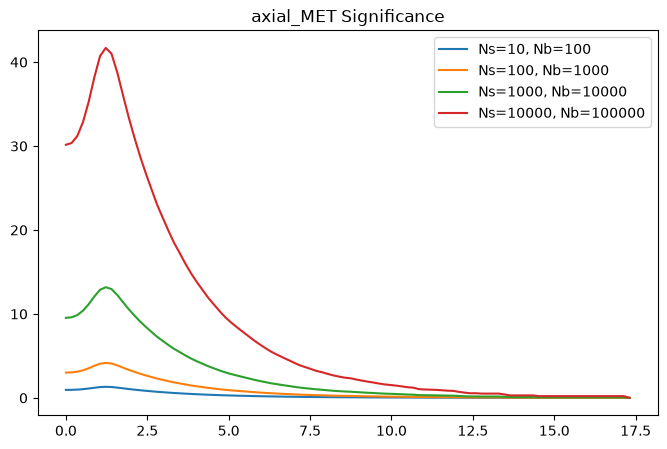

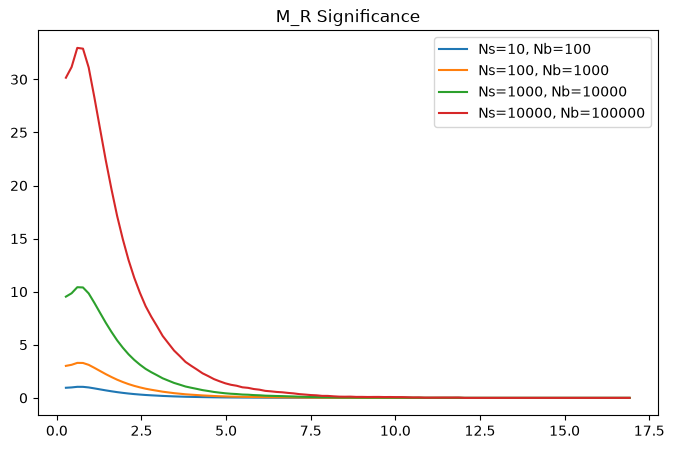

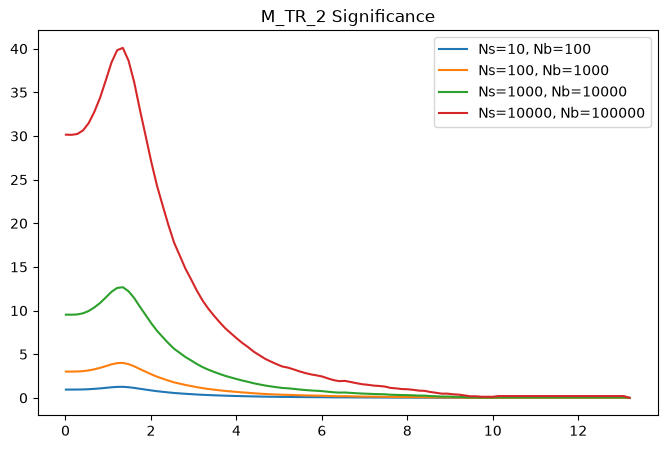

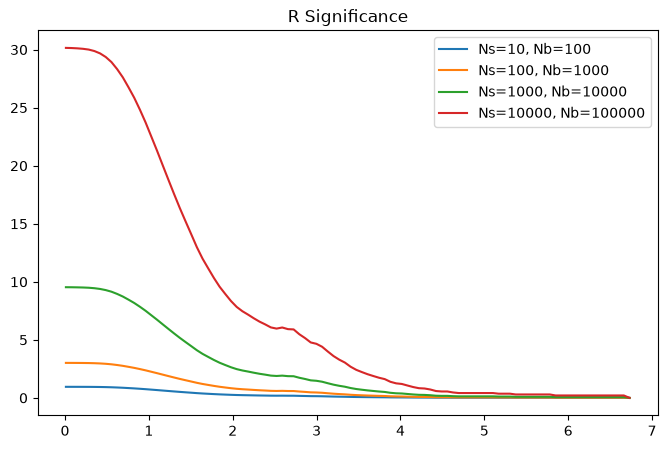

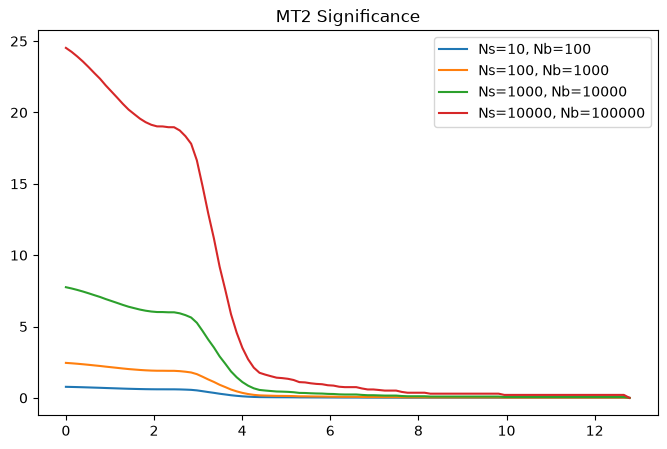

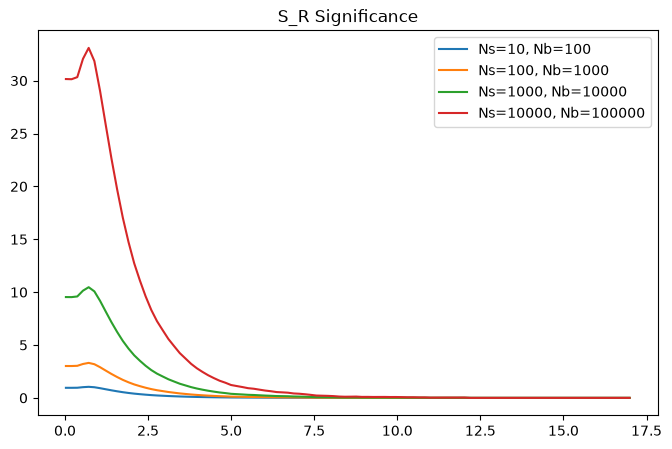

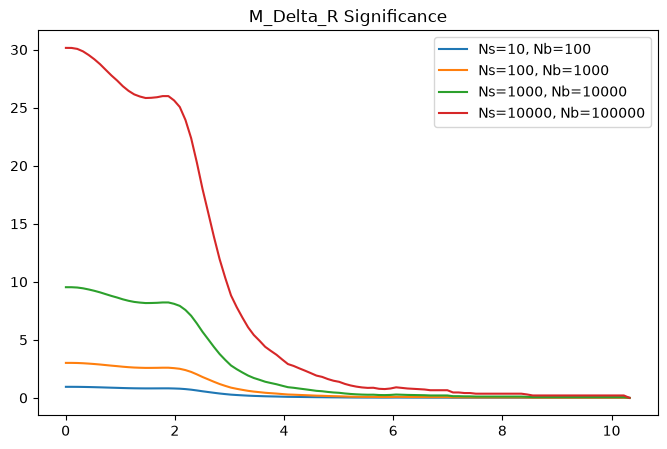

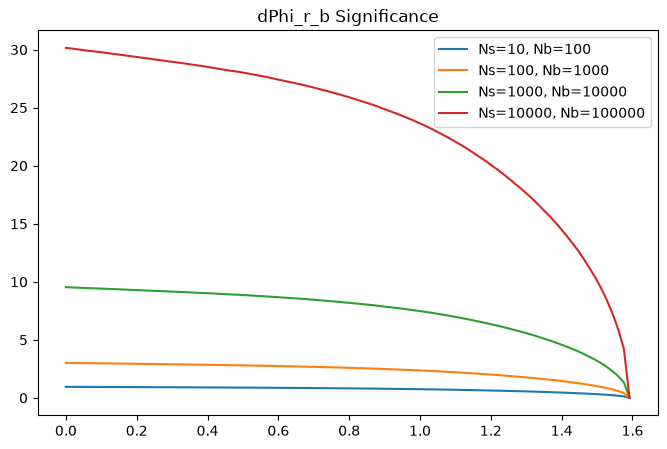

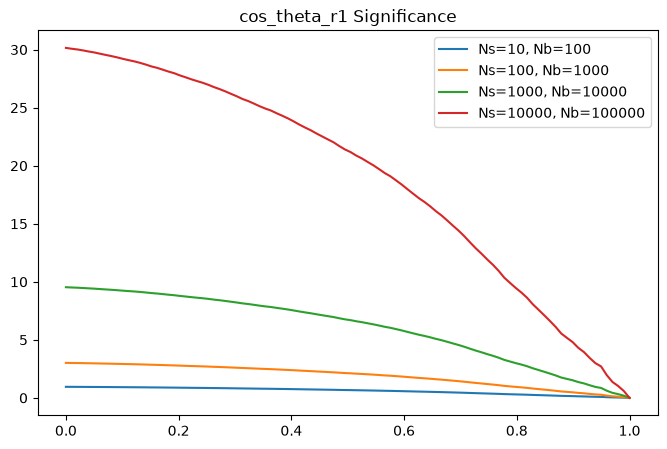

In [30]:
# Exercise 5.3
scenarios = [(10, 100), (100, 1000), (1000, 10000), (10000, 100000)]

def significance(tpr, fpr, ns, nb):
    ns_prime = np.array(tpr) * ns
    nb_prime = np.array(fpr) * nb

    total = ns_prime + nb_prime

    return np.divide(
        ns_prime,
        np.sqrt(total),
        out=np.zeros_like(ns_prime),
        where=total > 0
    )


for var in VarNames[1:]:
    selection = selections[var]

    if selection.startswith("abs"):
        thresholds = np.linspace(0, df[var].abs().max(), 100)
    else:
        thresholds = np.linspace(df[var].min(), df[var].max(), 100)

    tpr, fpr = efficiencies(df_sig, df_bkg, var, thresholds, selection)

    plt.figure(figsize=(8, 5))

    for ns, nb in scenarios:
        sig = significance(tpr, fpr, ns, nb)

        plt.plot(thresholds, sig, label=f"Ns={ns}, Nb={nb}")

    plt.title(f"{var} Significance")
    plt.legend()
    plt.show()

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




# Exercise 6.1
1. MET > 1.5
2. |axial_MET| > 1.1
3. M_TR_2 > 1.3

In [31]:
# Exercise 6.2
cuts = [
    ("MET", 1.5),
    ("axial_MET", 1.1),
    ("M_TR_2", 1.3)
]

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

def cut_flow(df_sig, df_bkg, ns, nb):
    sig = df_sig.copy()
    bkg = df_bkg.copy()

    results = []

    def add_row(selection):
        eps_s = len(sig) / len(df_sig)
        eps_b = len(bkg) / len(df_bkg)

        ns_prime = eps_s * ns
        nb_prime = eps_b * nb

        total = ns_prime + nb_prime
        significance = ns_prime / np.sqrt(total) if total > 0 else 0

        results.append([
            selection, eps_s, eps_b,
            ns_prime, nb_prime, significance
        ])

    add_row("No cuts")

    for var, xc in cuts:
        if var == "axial_MET":
            sig = sig[sig[var].abs() > xc]
            bkg = bkg[bkg[var].abs() > xc]
            selection = f"|{var}| > {xc}"
        else:
            sig = sig[sig[var] > xc]
            bkg = bkg[bkg[var] > xc]
            selection = f"{var} > {xc}"

        add_row(selection)

    return pd.DataFrame(
        results,
        columns=[
            "Selection", "Signal Efficiency",
            "Background Efficiency", "N_S'",
            "N_B'", "Significance"
        ]
    )


for ns, nb in scenarios:
    print(f"\nScenario: N_S = {ns}, N_B = {nb}")
    display(cut_flow(df_sig, df_bkg, ns, nb).round(4))


Scenario: N_S = 10, N_B = 100


,Selection,Signal Efficiency,Background Efficiency,N_S',N_B',Significance
0,No cuts,1.0000,1.0000,10.0000,100.0000,0.9535
1,MET > 1.5,0.3400,0.0177,3.4005,1.7651,1.4962
2,|axial_MET| > 1.1,0.2510,0.0127,2.5099,1.2679,1.2913
3,M_TR_2 > 1.3,0.1803,0.0101,1.8029,1.0127,1.0744



Scenario: N_S = 100, N_B = 1000


,Selection,Signal Efficiency,Background Efficiency,N_S',N_B',Significance
0,No cuts,1.0000,1.0000,100.0000,1000.0000,3.0151
1,MET > 1.5,0.3400,0.0177,34.0047,17.6506,4.7313
2,|axial_MET| > 1.1,0.2510,0.0127,25.0989,12.6794,4.0835
3,M_TR_2 > 1.3,0.1803,0.0101,18.0287,10.1272,3.3977



Scenario: N_S = 1000, N_B = 10000


,Selection,Signal Efficiency,Background Efficiency,N_S',N_B',Significance
0,No cuts,1.0000,1.0000,1000.0000,10000.0000,9.5346
1,MET > 1.5,0.3400,0.0177,340.0467,176.5064,14.9617
2,|axial_MET| > 1.1,0.2510,0.0127,250.9891,126.7936,12.9132
3,M_TR_2 > 1.3,0.1803,0.0101,180.2875,101.2724,10.7444



Scenario: N_S = 10000, N_B = 100000


,Selection,Signal Efficiency,Background Efficiency,N_S',N_B',Significance
0,No cuts,1.0000,1.0000,10000.0000,100000.0000,30.1511
1,MET > 1.5,0.3400,0.0177,3400.4667,1765.0644,47.3131
2,|axial_MET| > 1.1,0.2510,0.0127,2509.8912,1267.9360,40.8351
3,M_TR_2 > 1.3,0.1803,0.0101,1802.8747,1012.7237,33.9766


In [35]:
# Exercise 6.3
# Identify the strongest correlated pair
corr = df[VarNames[1:]].corr()
corr_abs = corr.abs().copy()
np.fill_diagonal(corr_abs.values, 0)

var1, var2 = corr_abs.stack().idxmax()

print("Strongest correlated pair:", var1, "and", var2)
print("Correlation coefficient:", corr.loc[var1, var2])


def apply_cut(data, var, xc):
    selection = selections[var]

    if selection == ">":
        return data[data[var] > xc]
    elif selection == "<":
        return data[data[var] < xc]
    elif selection == "abs>":
        return data[data[var].abs() > xc]
    elif selection == "abs<":
        return data[data[var].abs() < xc]


def optimize_cut(sig, bkg, var, ns, nb):
    selection = selections[var]

    if selection.startswith("abs"):
        thresholds = np.linspace(0, df[var].abs().max(), 100)
    else:
        thresholds = np.linspace(df[var].min(), df[var].max(), 100)

    best_xc = None
    best_significance = -1

    for xc in thresholds:
        sig_cut = apply_cut(sig, var, xc)
        bkg_cut = apply_cut(bkg, var, xc)

        eps_s = len(sig_cut) / len(df_sig)
        eps_b = len(bkg_cut) / len(df_bkg)

        ns_prime = eps_s * ns
        nb_prime = eps_b * nb

        total = ns_prime + nb_prime

        significance = (
            ns_prime / np.sqrt(total) if total > 0 else 0
        )

        if significance > best_significance:
            best_significance = significance
            best_xc = xc

    return best_xc, best_significance


def combined_significance(sig, bkg, ns, nb):
    eps_s = len(sig) / len(df_sig)
    eps_b = len(bkg) / len(df_bkg)

    ns_prime = eps_s * ns
    nb_prime = eps_b * nb

    total = ns_prime + nb_prime

    return ns_prime / np.sqrt(total) if total > 0 else 0


def compare_order(first, second, ns, nb):
    # Optimize both variables independently, as in Exercise 5.3
    xc1, _ = optimize_cut(df_sig, df_bkg, first, ns, nb)
    xc2_independent, _ = optimize_cut(df_sig, df_bkg, second, ns, nb)

    # Apply the first selection
    sig = apply_cut(df_sig, first, xc1)
    bkg = apply_cut(df_bkg, first, xc1)

    # Significance using both independently optimized thresholds
    sig_ind = apply_cut(sig, second, xc2_independent)
    bkg_ind = apply_cut(bkg, second, xc2_independent)

    independent_sig = combined_significance(
        sig_ind, bkg_ind, ns, nb
    )

    # Re-optimize the second variable after the first selection
    xc2_new, optimized_sig = optimize_cut(
        sig, bkg, second, ns, nb
    )

    return {
        "Scenario": f"{ns}/{nb}",
        "First Variable": first,
        "First Threshold": xc1,
        "Second Variable": second,
        "Original Second Threshold": xc2_independent,
        "New Second Threshold": xc2_new,
        "Original Significance": independent_sig,
        "Optimized Significance": optimized_sig,
        "Improvement": optimized_sig - independent_sig
    }


results = []

for ns, nb in scenarios:
    results.append(compare_order(var1, var2, ns, nb))
    results.append(compare_order(var2, var1, ns, nb))

display(pd.DataFrame(results).round(4))

Strongest correlated pair: M_R and S_R
Correlation coefficient: 0.9811549413666396


,Scenario,First Variable,First Threshold,Second Variable,Original Second Threshold,New Second Threshold,Original Significance,Optimized Significance,Improvement
0,10/100,M_R,0.6037,S_R,0.7127,0.0273,1.0323,1.0423,0.0100
1,10/100,S_R,0.7127,M_R,0.6037,0.2673,1.0323,1.0466,0.0143
2,100/1000,M_R,0.6037,S_R,0.7127,0.0273,3.2645,3.2960,0.0315
3,100/1000,S_R,0.7127,M_R,0.6037,0.2673,3.2645,3.3097,0.0453
4,1000/10000,M_R,0.6037,S_R,0.7127,0.0273,10.3232,10.4228,0.0996
5,1000/10000,S_R,0.7127,M_R,0.6037,0.2673,10.3232,10.4663,0.1431
6,10000/100000,M_R,0.6037,S_R,0.7127,0.0273,32.6450,32.9598,0.3149
7,10000/100000,S_R,0.7127,M_R,0.6037,0.2673,32.6450,33.0975,0.4525


The correlation matrix shows that M_R and S_R are strongly positively correlated, with a correlation coefficient of approximately 0.9812. Because these observables are highly correlated, optimizing their selection thresholds independently may not produce the highest combined significance. Applying the M_R selection first and then re-optimizing S_R increased the significance from 32.6450 to 32.9598 for the largest scenario. Reversing the order and applying S_R first, followed by re-optimizing M_R, increased the significance to 33.0975. Both approaches improved significance compared to the independently optimized selections, but applying S_R first produced slightly better results. This demonstrates that correlations between observables can affect optimal selection thresholds and that the order of sequential optimization can influence the final significance.

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



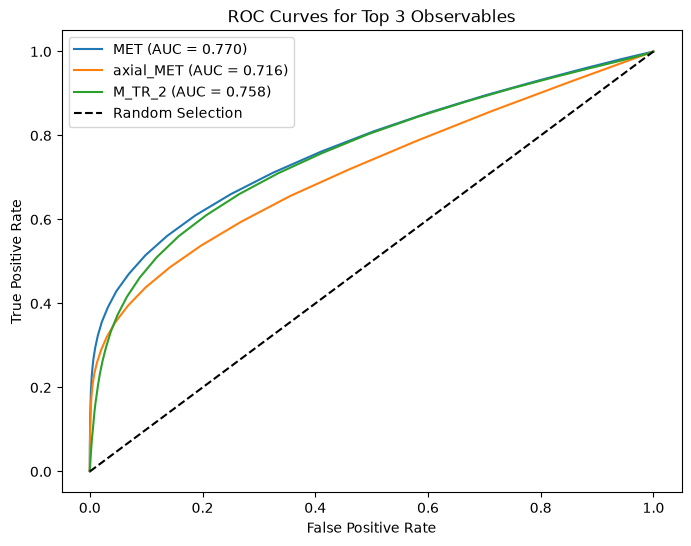

In [36]:
# Exercise 7.1
def plot_roc(observables, sig_data=df_sig, bkg_data=df_bkg, title="ROC Curves"):
    plt.figure(figsize=(8, 6))

    for var in observables:
        selection = selections[var]

        if selection.startswith("abs"):
            thresholds = np.linspace(0, df[var].abs().max(), 200)
        else:
            thresholds = np.linspace(df[var].min(), df[var].max(), 200)

        tpr, fpr = efficiencies(
            sig_data, bkg_data, var, thresholds, selection
        )

        # Sort by FPR for AUC calculation
        order = np.argsort(fpr)
        fpr_sorted = np.array(fpr)[order]
        tpr_sorted = np.array(tpr)[order]

        area = np.trapezoid(tpr_sorted, fpr_sorted)

        plt.plot(
            fpr_sorted, tpr_sorted,
            label=f"{var} (AUC = {area:.3f})"
        )

    plt.plot([0, 1], [0, 1], "k--", label="Random Selection")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend()
    plt.show()


plot_roc(["MET", "axial_MET", "M_TR_2"],
         title="ROC Curves for Top 3 Observables")

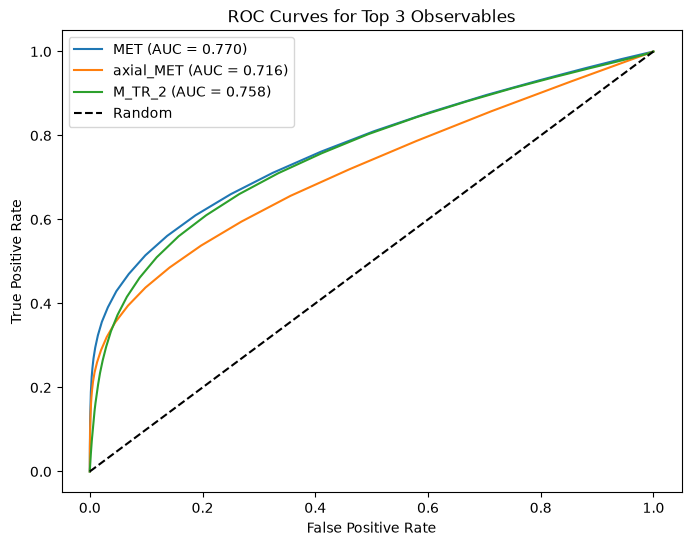

In [39]:
# Exercise 7.2
def plot_roc(observables, sig_data, bkg_data, title="ROC Curves"):
    plt.figure(figsize=(8, 6))

    for var in observables:
        selection = selections[var]

        if selection.startswith("abs"):
            maximum = max(sig_data[var].abs().max(),
                          bkg_data[var].abs().max())
            thresholds = np.linspace(0, maximum, 200)
        else:
            minimum = min(sig_data[var].min(), bkg_data[var].min())
            maximum = max(sig_data[var].max(), bkg_data[var].max())
            thresholds = np.linspace(minimum, maximum, 200)

        tpr, fpr = efficiencies(
            sig_data, bkg_data, var, thresholds, selection
        )

        fpr = np.array(fpr)
        tpr = np.array(tpr)

        # Sort values before calculating the area
        order = np.argsort(fpr)
        fpr = fpr[order]
        tpr = tpr[order]

        # Include ROC endpoints
        fpr = np.concatenate(([0], fpr, [1]))
        tpr = np.concatenate(([0], tpr, [1]))

        area = np.trapezoid(tpr, fpr)

        plt.plot(fpr, tpr, label=f"{var} (AUC = {area:.3f})")

    plt.plot([0, 1], [0, 1], "k--", label="Random")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend()
    plt.show()

plot_roc(
    ["MET", "axial_MET", "M_TR_2"],
    df_sig,
    df_bkg,
    title="ROC Curves for Top 3 Observables"
)

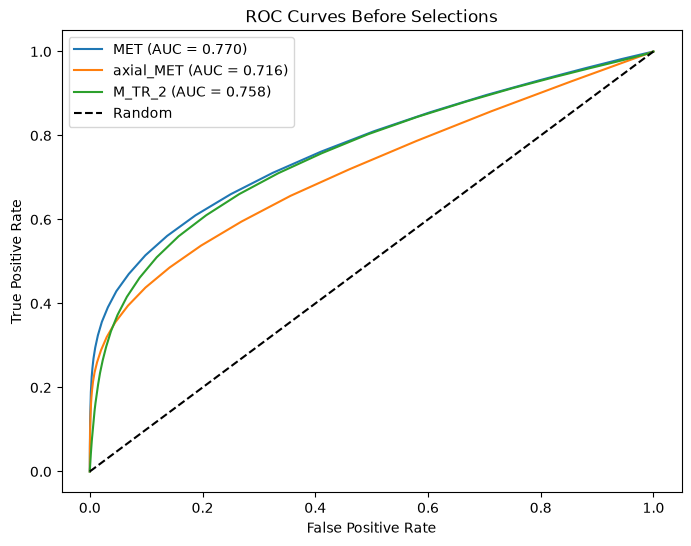

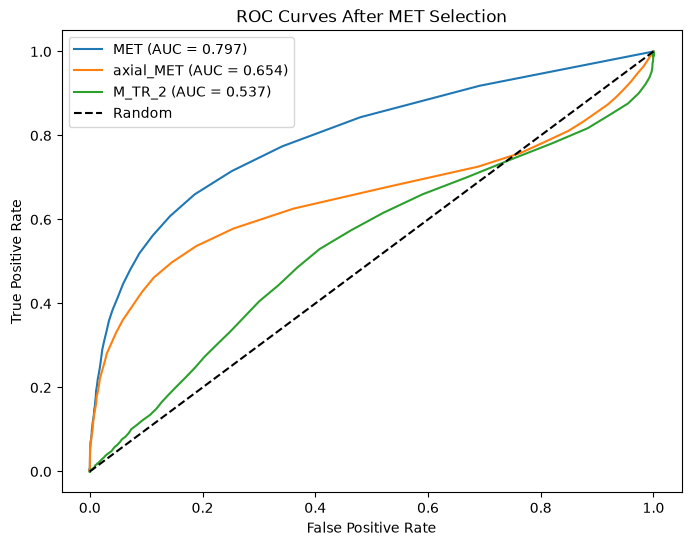

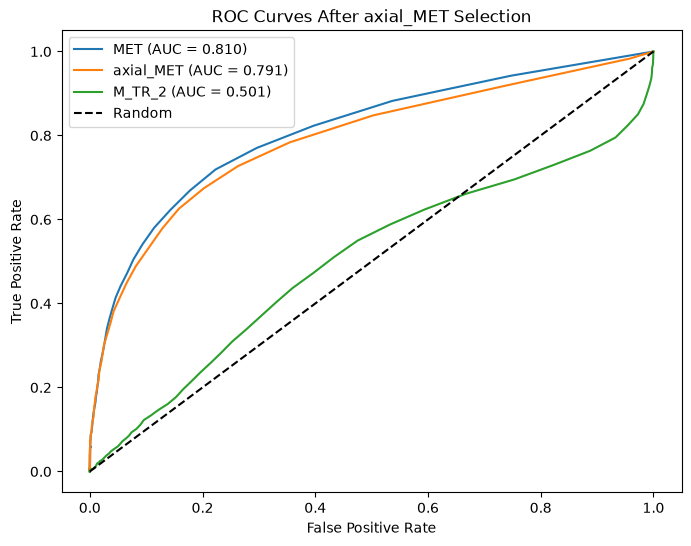

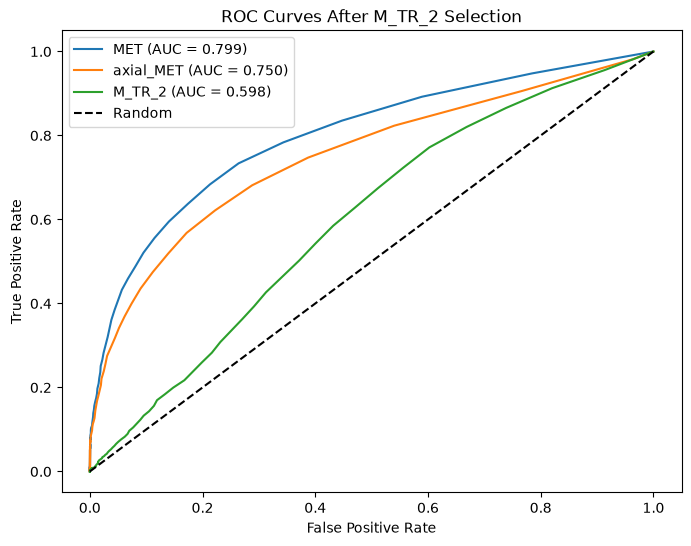

In [40]:
# Exercise 7.3
sig = df_sig.copy()
bkg = df_bkg.copy()

observables = ["MET", "axial_MET", "M_TR_2"]

# Before any selections
plot_roc(observables, sig, bkg, title="ROC Curves Before Selections")

# Apply each selection successively
for var, xc in cuts:
    if var == "axial_MET":
        sig = sig[sig[var].abs() > xc]
        bkg = bkg[bkg[var].abs() > xc]
    else:
        sig = sig[sig[var] > xc]
        bkg = bkg[bkg[var] > xc]

    plot_roc(
        observables,
        sig,
        bkg,
        title=f"ROC Curves After {var} Selection"
    )

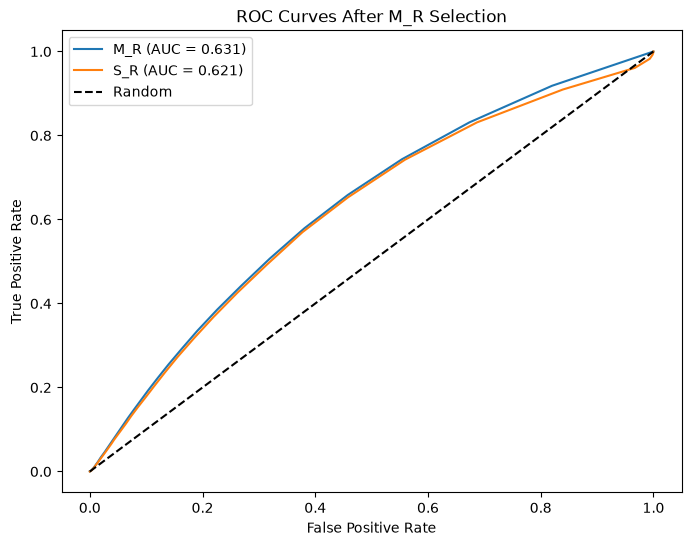

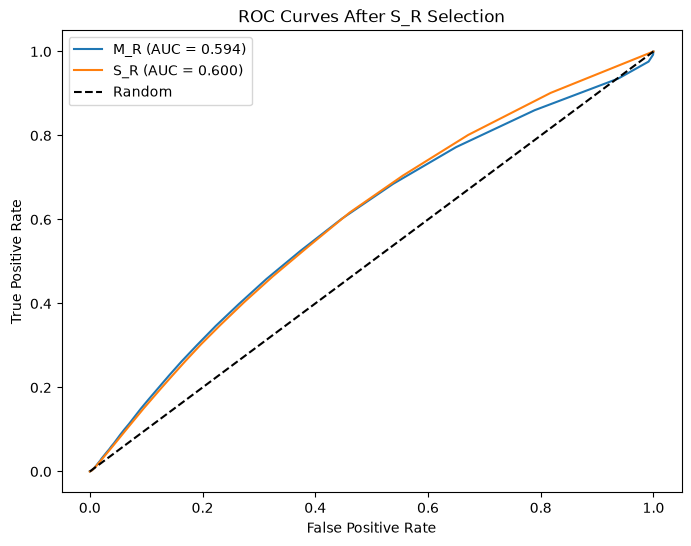

In [41]:
# Exercise 7.4
# Order 1: Select M_R first
sig1 = df_sig[df_sig["M_R"] > 0.6037]
bkg1 = df_bkg[df_bkg["M_R"] > 0.6037]

plot_roc(
    ["M_R", "S_R"],
    sig1,
    bkg1,
    title="ROC Curves After M_R Selection"
)

# Order 2: Select S_R first
sig2 = df_sig[df_sig["S_R"] > 0.7127]
bkg2 = df_bkg[df_bkg["S_R"] > 0.7127]

plot_roc(
    ["M_R", "S_R"],
    sig2,
    bkg2,
    title="ROC Curves After S_R Selection"
)

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [42]:
# Exercise 8.1
observables = VarNames[1:]

X_sig = df_sig[observables].to_numpy()
X_bkg = df_bkg[observables].to_numpy()

# Mean vectors for signal and background
m_sig = np.mean(X_sig, axis=0)
m_bkg = np.mean(X_bkg, axis=0)

# Between-class covariance matrix
mean_diff = m_sig - m_bkg
S_B = np.outer(mean_diff, mean_diff)

# Within-class covariance matrix
sig_centered = X_sig - m_sig
bkg_centered = X_bkg - m_bkg

S_W = sig_centered.T @ sig_centered + bkg_centered.T @ bkg_centered

print("Between-class covariance matrix:")
display(pd.DataFrame(S_B, index=observables, columns=observables))

print("Within-class covariance matrix:")
display(pd.DataFrame(S_W, index=observables, columns=observables))

Between-class covariance matrix:


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.287970,4.589223e-04,4.674674e-04,0.138149,0.001541,3.660956e-04,0.413461,-6.366181e-04,0.271136,0.085466,0.182332,0.266558,0.055323,0.073782,0.174242,0.184116,0.015406,0.056628
l_1_eta,0.000459,7.313592e-07,7.449771e-07,0.000220,0.000002,5.834263e-07,0.000659,-1.014543e-06,0.000432,0.000136,0.000291,0.000425,0.000088,0.000118,0.000278,0.000293,0.000025,0.000090
l_1_phi,0.000467,7.449771e-07,7.588486e-07,0.000224,0.000003,5.942897e-07,0.000671,-1.033434e-06,0.000440,0.000139,0.000296,0.000433,0.000090,0.000120,0.000283,0.000299,0.000025,0.000092
l_2_pT,0.138149,2.201599e-04,2.242593e-04,0.066274,0.000739,1.756279e-04,0.198351,-3.054063e-04,0.130073,0.041001,0.087470,0.127876,0.026540,0.035396,0.083589,0.088327,0.007391,0.027166
l_2_eta,0.001541,2.455298e-06,2.501015e-06,0.000739,0.000008,1.958662e-06,0.002212,-3.405995e-06,0.001451,0.000457,0.000975,0.001426,0.000296,0.000395,0.000932,0.000985,0.000082,0.000303
l_2_phi,0.000366,5.834263e-07,5.942897e-07,0.000176,0.000002,4.654160e-07,0.000526,-8.093304e-07,0.000345,0.000109,0.000232,0.000339,0.000070,0.000094,0.000222,0.000234,0.000020,0.000072
MET,0.413461,6.589106e-04,6.711795e-04,0.198351,0.002212,5.256320e-04,0.593639,-9.140423e-04,0.389291,0.122710,0.261788,0.382718,0.079431,0.105935,0.250173,0.264350,0.022119,0.081305
MET_phi,-0.000637,-1.014543e-06,-1.033434e-06,-0.000305,-0.000003,-8.093304e-07,-0.000914,1.407377e-06,-0.000599,-0.000189,-0.000403,-0.000589,-0.000122,-0.000163,-0.000385,-0.000407,-0.000034,-0.000125
MET_rel,0.271136,4.320949e-04,4.401405e-04,0.130073,0.001451,3.446946e-04,0.389291,-5.994030e-04,0.255286,0.080470,0.171673,0.250975,0.052089,0.069469,0.164056,0.173354,0.014505,0.053318
axial_MET,0.085466,1.362020e-04,1.387381e-04,0.041001,0.000457,1.086523e-04,0.122710,-1.889397e-04,0.080470,0.025365,0.054114,0.079111,0.016419,0.021898,0.051713,0.054643,0.004572,0.016806


Within-class covariance matrix:


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,197992.314222,-255.306615,-19.720051,135369.126926,-365.670849,323.221047,62890.484946,-389.327463,15103.484874,-15475.839600,159581.488411,110521.397574,-36718.849769,-15358.632160,149663.061620,26013.428669,-25386.959587,4051.875587
l_1_eta,-255.306615,502149.623006,-428.906989,-108.782977,204155.733837,-521.076631,-1155.282987,-294.357629,-738.924286,-571.353000,-312.983919,-387.193278,139.704991,198.964347,-336.474893,-530.158934,-373.212146,149.612912
l_1_phi,-19.720051,-428.906989,501985.583989,628.639491,125.046741,-133404.896001,299.862992,-92401.675464,298.463939,-953.566382,494.789240,380.674792,89.649144,515.276528,696.768816,413.513165,494.047379,118.137455
l_2_pT,135369.126926,-108.782977,628.639491,204517.454736,-379.537641,56.139663,15102.895278,-742.970965,-16413.989358,20575.119612,151858.466763,65595.995445,-52970.097073,-38836.833053,150592.986841,-8106.923835,-2834.781223,-17327.478373
l_2_eta,-365.670849,204155.733837,125.046741,-379.537641,503130.198981,220.550544,-83.777970,-160.801601,362.067173,-434.987657,-424.931720,-167.598626,123.568959,650.442433,-455.014623,212.934766,-163.667245,110.560041
l_2_phi,323.221047,-521.076631,-133404.896001,56.139663,220.550544,501898.100374,-217.238662,-17717.015666,680.725023,-913.738111,351.181900,212.392348,266.841154,1117.928545,425.719861,634.239598,-123.035647,9.583066
MET,62890.484946,-1155.282987,299.862992,15102.895278,-83.777970,-217.238662,307430.190195,-1282.593998,224914.071362,61744.917531,39762.776556,135086.679216,84095.427281,64241.773945,51715.188224,124755.337402,70094.967950,26452.977638
MET_phi,-389.327463,-294.357629,-92401.675464,-742.970965,-160.801601,-17717.015666,-1282.593998,501655.398054,-2373.187735,-197.440345,-691.535845,-527.346940,-99.582582,62.182577,-805.554513,-234.397288,-850.300479,75.242987
MET_rel,15103.484874,-738.924286,298.463939,-16413.989358,362.067173,680.725023,224914.071362,-2373.187735,363552.912060,-69914.850974,531.001209,119840.321435,117945.325156,195765.226740,20791.938560,185851.266182,71418.908994,21040.095977
axial_MET,-15475.839600,-571.353000,-953.566382,20575.119612,-434.987657,-913.738111,61744.917531,-197.440345,-69914.850974,499537.193740,1849.679839,-102328.897303,-92488.124909,-233217.180850,-27110.895967,-123320.090749,-13123.956285,-28953.700291


Fisher coefficients:


,Observable,Coefficient
0,l_1_pT,2.268330e-06
1,l_1_eta,5.636884e-09
2,l_1_phi,2.104239e-09
3,l_2_pT,9.955830e-07
4,l_2_eta,3.484522e-09
5,l_2_phi,2.707626e-09
6,MET,1.651854e-06
7,MET_phi,2.742418e-09
8,MET_rel,1.397233e-07
9,axial_MET,2.642057e-07


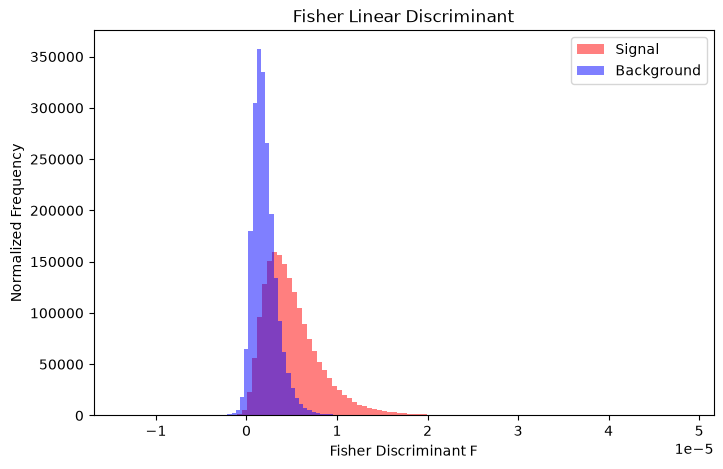

In [43]:
# Exercise 8.2
# Fisher linear discriminant coefficients
w = np.linalg.solve(S_W, mean_diff)

print("Fisher coefficients:")
display(pd.DataFrame({"Observable": observables, "Coefficient": w}))

# Fisher discriminant values
F_sig = X_sig @ w
F_bkg = X_bkg @ w

plt.figure(figsize=(8, 5))

plt.hist(F_sig, bins=100, density=True, alpha=0.5,
         color="red", label="Signal")

plt.hist(F_bkg, bins=100, density=True, alpha=0.5,
         color="blue", label="Background")

plt.xlabel("Fisher Discriminant F")
plt.ylabel("Normalized Frequency")
plt.title("Fisher Linear Discriminant")
plt.legend()
plt.show()

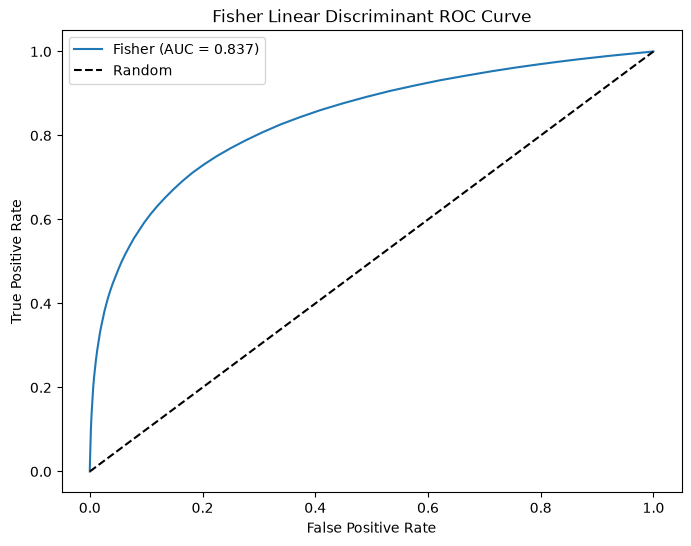

In [44]:
# Exercise 8.3
thresholds = np.linspace(
    min(F_sig.min(), F_bkg.min()),
    max(F_sig.max(), F_bkg.max()),
    500
)

tpr = []
fpr = []

for xc in thresholds:
    tpr.append(np.mean(F_sig > xc))
    fpr.append(np.mean(F_bkg > xc))

tpr = np.array(tpr)
fpr = np.array(fpr)

order = np.argsort(fpr)

fpr_sorted = np.concatenate(([0], fpr[order], [1]))
tpr_sorted = np.concatenate(([0], tpr[order], [1]))

area = np.trapezoid(tpr_sorted, fpr_sorted)

plt.figure(figsize=(8, 6))
plt.plot(fpr_sorted, tpr_sorted, label=f"Fisher (AUC = {area:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Fisher Linear Discriminant ROC Curve")
plt.legend()
plt.show()

In [45]:
# Exercise 8.4
scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

results = []

for ns, nb in scenarios:
    ns_prime = tpr * ns
    nb_prime = fpr * nb

    total = ns_prime + nb_prime

    significance = np.divide(
        ns_prime,
        np.sqrt(total),
        out=np.zeros_like(ns_prime),
        where=total > 0
    )

    best_index = np.argmax(significance)

    results.append({
        "N_S": ns,
        "N_B": nb,
        "Optimal Threshold": thresholds[best_index],
        "Maximum Significance": significance[best_index]
    })

display(pd.DataFrame(results).round(4))

,N_S,N_B,Optimal Threshold,Maximum Significance
0,10,100,0.0,1.5313
1,100,1000,0.0,4.8424
2,1000,10000,0.0,15.3131
3,10000,100000,0.0,48.4243
